# Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import shap
import warnings
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score




# Data Loading

In [2]:
df = pd.read_csv('data/ENB2012_data.csv')

df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


# Data Description

X1 Relative Compactness

X2 Surface Area 

X3 Wall Area

X4 Roof Area

X5 Overall Height

X6 Orientation

X7 Glazing Area

X8 Glazing Area Distribution

y1 Heating Load

y2 Cooling Load

In [3]:
df.columns = ['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Orientation', 'Glazing_Area', 'Glazing_Area_Distribution', 'Heating_Load', 'Cooling_Load']

In [4]:
df.describe()

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307201,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090196,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


In [5]:
df.dtypes

Relative_Compactness         float64
Surface_Area                 float64
Wall_Area                    float64
Roof_Area                    float64
Overall_Height               float64
Orientation                    int64
Glazing_Area                 float64
Glazing_Area_Distribution      int64
Heating_Load                 float64
Cooling_Load                 float64
dtype: object

# Missing Values

In [6]:
missing = df.isnull().sum()
missing = missing[missing > 0]

print("Missing Values:")
print(missing)
print(f"\nTotal missing: {missing.sum()}")

Missing Values:
Series([], dtype: int64)

Total missing: 0


# Duplicate Values and Dropping a Column

In [7]:
print(f'Shape of Dataset before drop duplicated Row is: {df.shape}')

df = df.drop_duplicates()

print(f'Shape of Dataset after drop duplicated Row is: {df.shape}')


df = df.drop(columns=['Surface_Area'])

print(f'Shape of Dataset After Drop Surface Area Row is: {df.shape}')


Shape of Dataset before drop duplicated Row is: (768, 10)
Shape of Dataset after drop duplicated Row is: (768, 10)
Shape of Dataset After Drop Surface Area Row is: (768, 9)


# Checking for Outliers

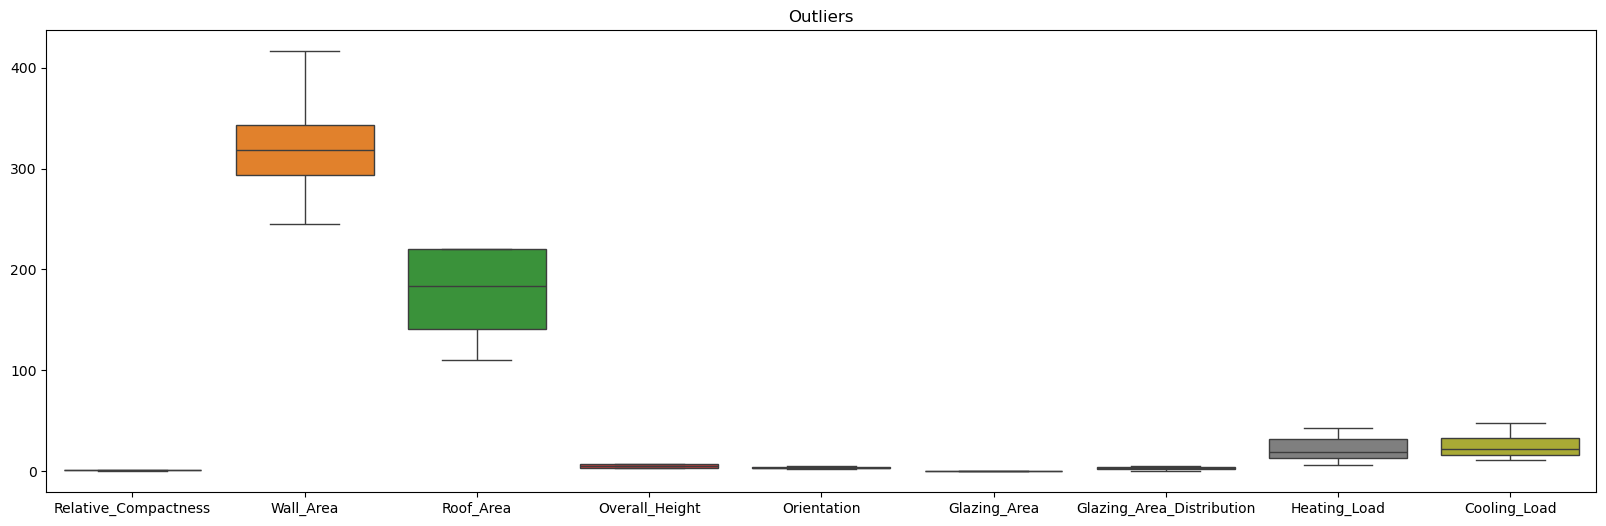

In [8]:
plt.figure(figsize = (20,6))
sns.boxplot(data = df)
plt.title("Outliers")
plt.show()

# Feature Engineering

In [9]:
df = pd.get_dummies(df, columns=['Orientation', 'Glazing_Area_Distribution'], 
                    prefix=['Orientation', 'Glazing'], 
                    drop_first=True)

rename_map = {
    'Orientation_3': 'Orientation_East',
    'Orientation_4': 'Orientation_South',
    'Orientation_5': 'Orientation_West',
    'Glazing_1': 'Glazing_Uniform',
    'Glazing_2': 'Glazing_North',
    'Glazing_3': 'Glazing_East',
    'Glazing_4': 'Glazing_South',
    'Glazing_5': 'Glazing_West'
}

df.rename(columns=rename_map, inplace=True)

print("New Dataframe Shape:", df.shape)
print("New Columns:", df.columns.tolist())
df.head()

New Dataframe Shape: (768, 15)
New Columns: ['Relative_Compactness', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Glazing_Area', 'Heating_Load', 'Cooling_Load', 'Orientation_East', 'Orientation_South', 'Orientation_West', 'Glazing_Uniform', 'Glazing_North', 'Glazing_East', 'Glazing_South', 'Glazing_West']


,Relative_Compactness,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Heating_Load,Cooling_Load,Orientation_East,Orientation_South,Orientation_West,Glazing_Uniform,Glazing_North,Glazing_East,Glazing_South,Glazing_West
0,0.98,294.0,110.25,7.0,0.0,15.55,21.33,False,False,False,False,False,False,False,False
1,0.98,294.0,110.25,7.0,0.0,15.55,21.33,True,False,False,False,False,False,False,False
2,0.98,294.0,110.25,7.0,0.0,15.55,21.33,False,True,False,False,False,False,False,False
3,0.98,294.0,110.25,7.0,0.0,15.55,21.33,False,False,True,False,False,False,False,False
4,0.90,318.5,122.50,7.0,0.0,20.84,28.28,False,False,False,False,False,False,False,False


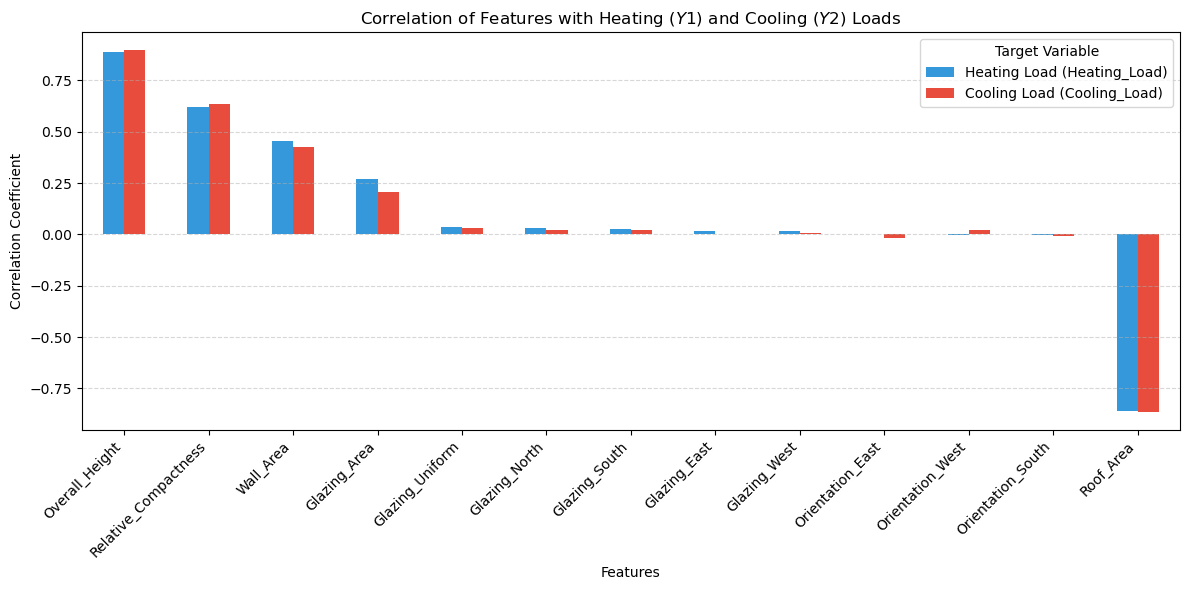

In [ ]:
corr_y1 = df.corr()['Heating_Load'].drop(['Heating_Load', 'Cooling_Load'])
corr_y2 = df.corr()['Cooling_Load'].drop(['Heating_Load', 'Cooling_Load'])

combined_corr = pd.DataFrame({
    'Heating Load (Heating_Load)': corr_y1,
    'Cooling Load (Cooling_Load)': corr_y2
})

combined_corr = combined_corr.sort_values(by='Heating Load (Heating_Load)', ascending=False)

combined_corr.plot(kind='bar', figsize=(12, 6), color=['#3498db', '#e74c3c'])

plt.title('Correlation of Features with Heating ($Y1$) and Cooling ($Y2$) Loads')
plt.ylabel('Correlation Coefficient')
plt.xlabel('Features')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Target Variable')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

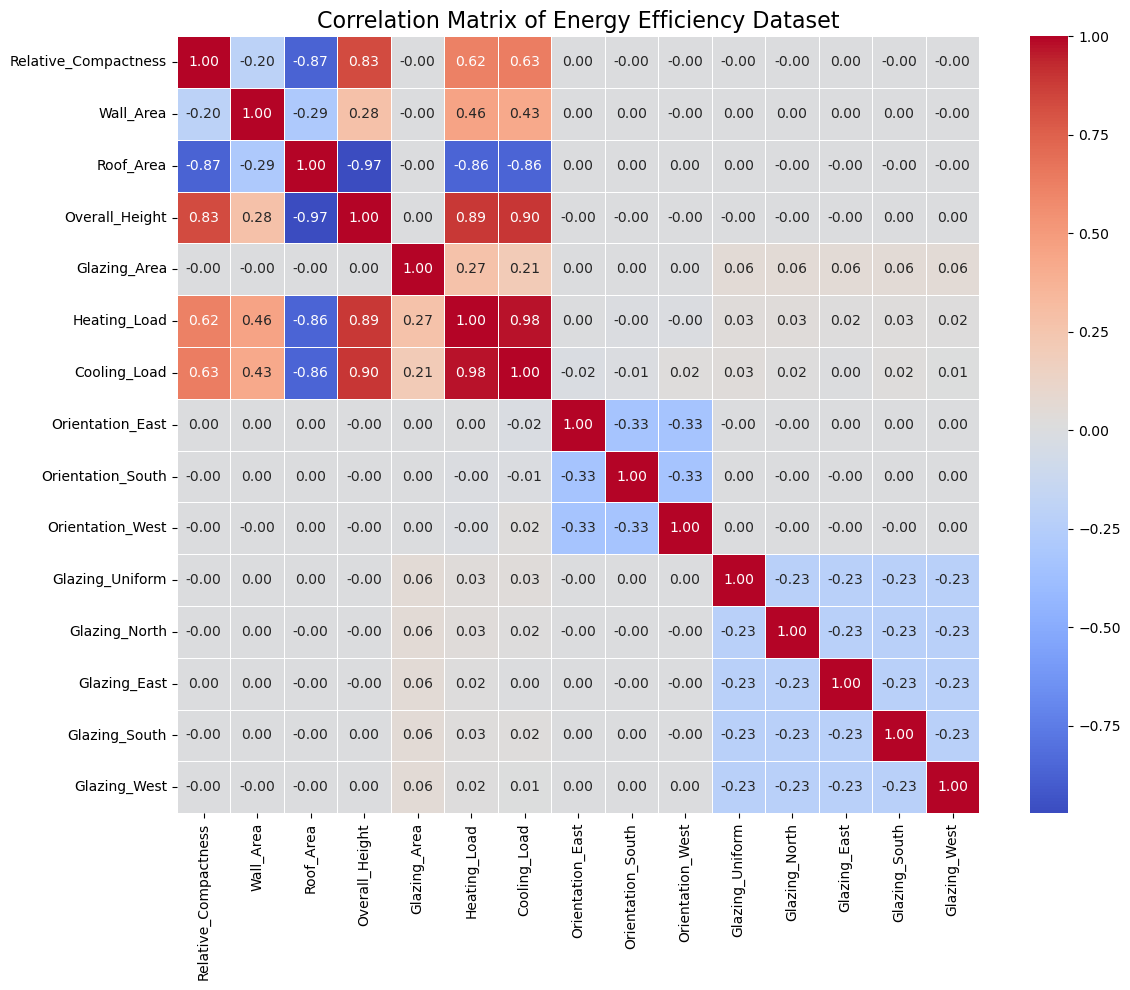

In [ ]:
corr_matrix = df.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Correlation Matrix of Energy Efficiency Dataset', fontsize=16)
plt.tight_layout()

plt.show()

# Histogram 

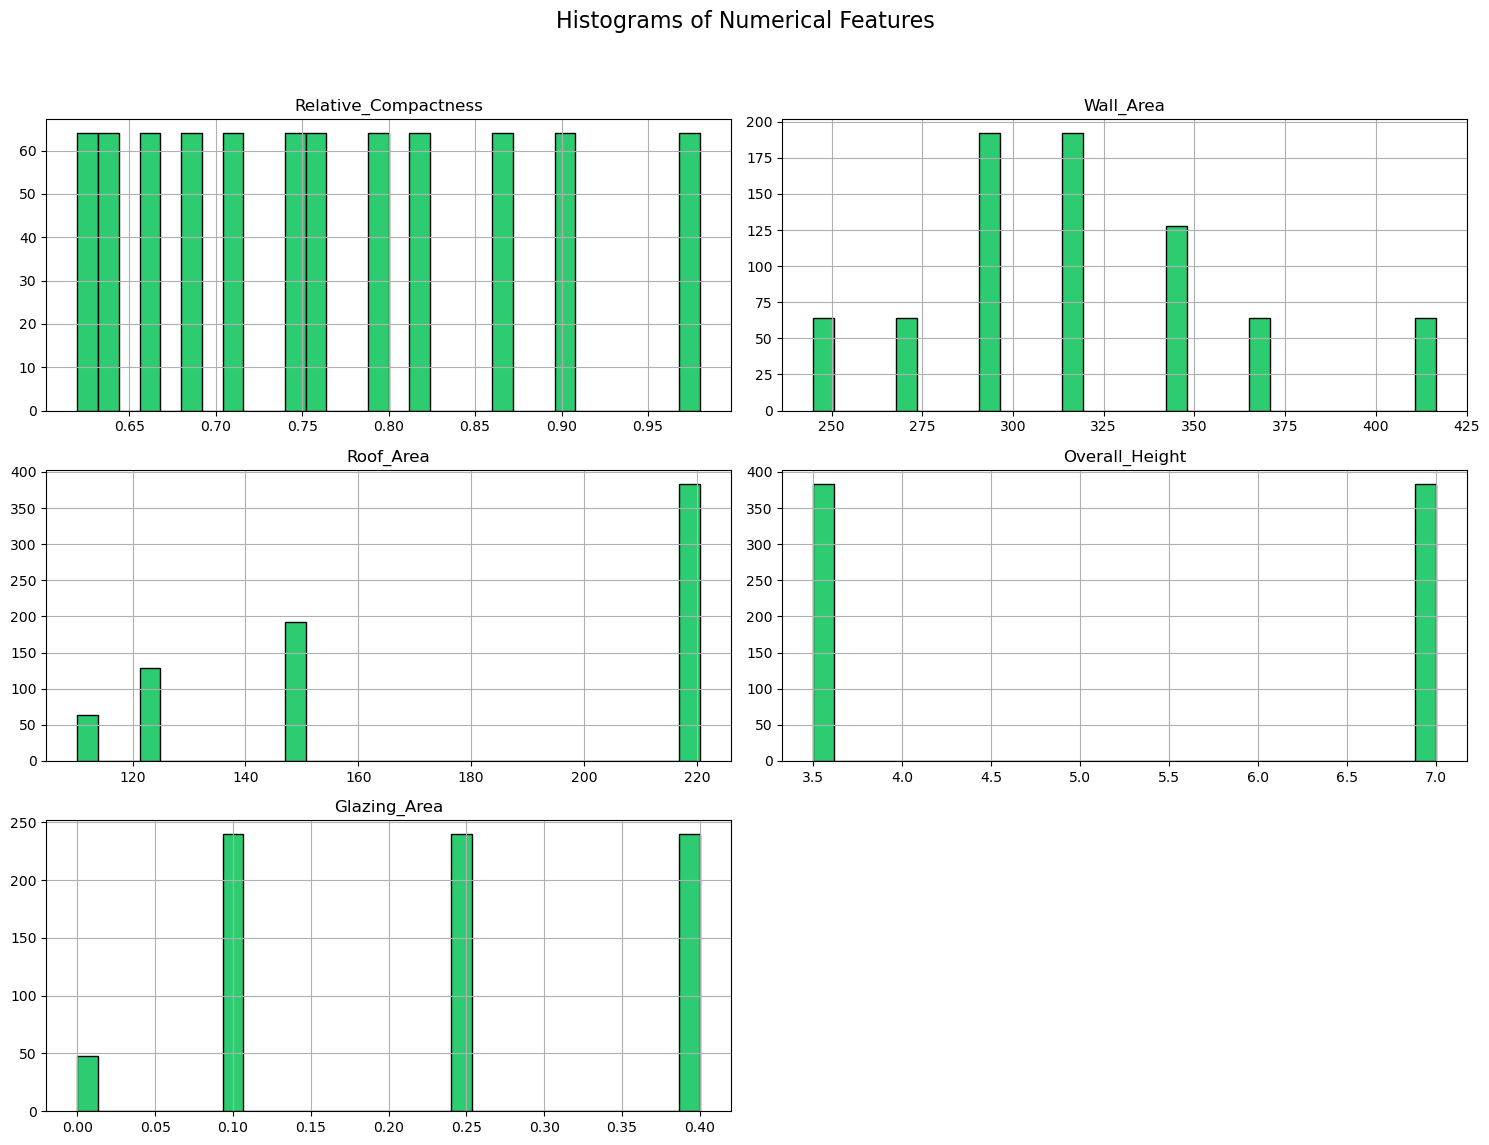

In [12]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
targets_to_remove = ['Heating_Load', 'Cooling_Load']

num_cols = [col for col in num_cols if col not in targets_to_remove]

df[num_cols].hist(figsize=(15, 12), bins=30, edgecolor='black', color='#2ecc71')

plt.suptitle("Histograms of Numerical Features", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# Scatter plots (Heating Load)

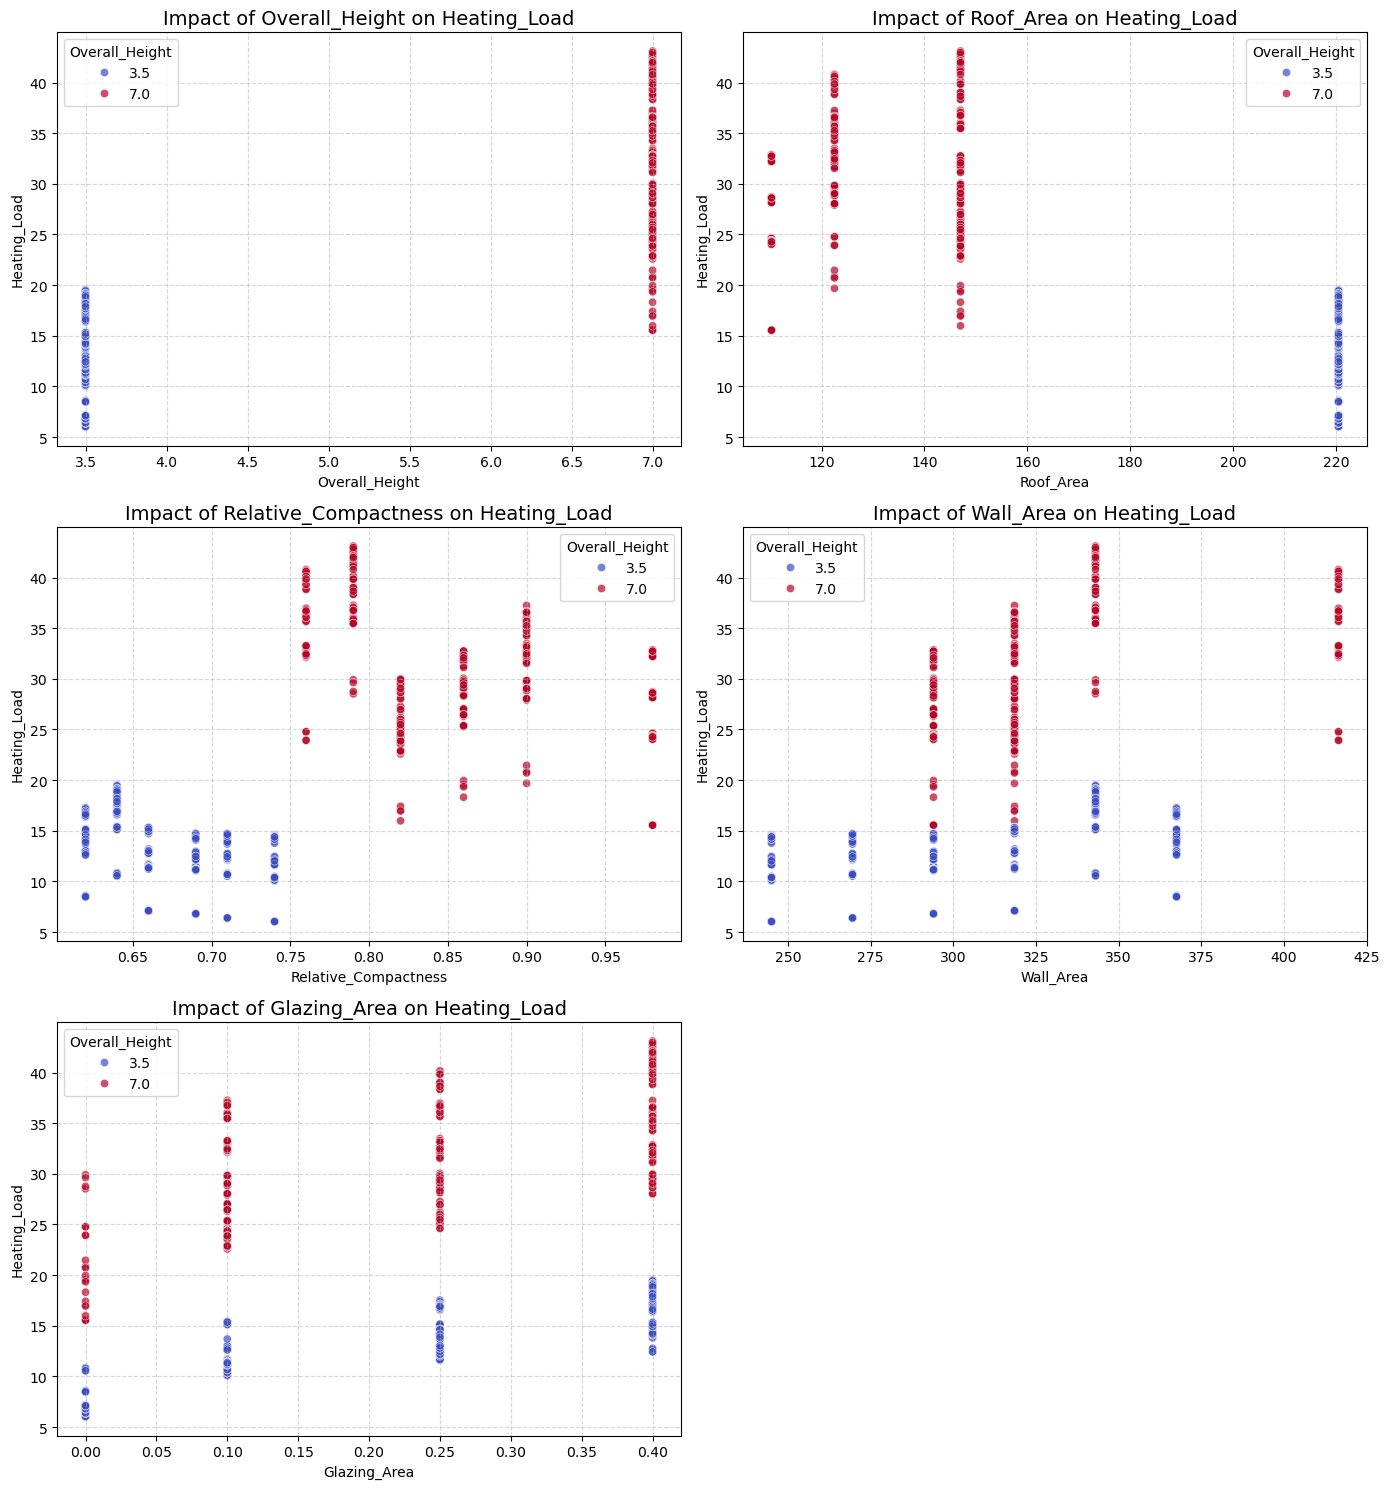

In [13]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

df.columns = df.columns.str.strip()

pairs = [
    ('Overall_Height', 'Heating_Load'),       
    ('Roof_Area', 'Heating_Load'),             
    ('Relative_Compactness', 'Heating_Load'),  
    ('Wall_Area', 'Heating_Load'),             
    ('Glazing_Area', 'Heating_Load')           
]

rows = math.ceil(len(pairs) / 2)
cols = 2

plt.figure(figsize=(14, 5 * rows))

for i, (x, y) in enumerate(pairs, 1):
    plt.subplot(rows, cols, i)
    sns.scatterplot(data=df, x=x, y=y, hue='Overall_Height', palette='coolwarm', alpha=0.7)
    plt.title(f"Impact of {x} on {y}", fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Scatter plots (Cooling Load)

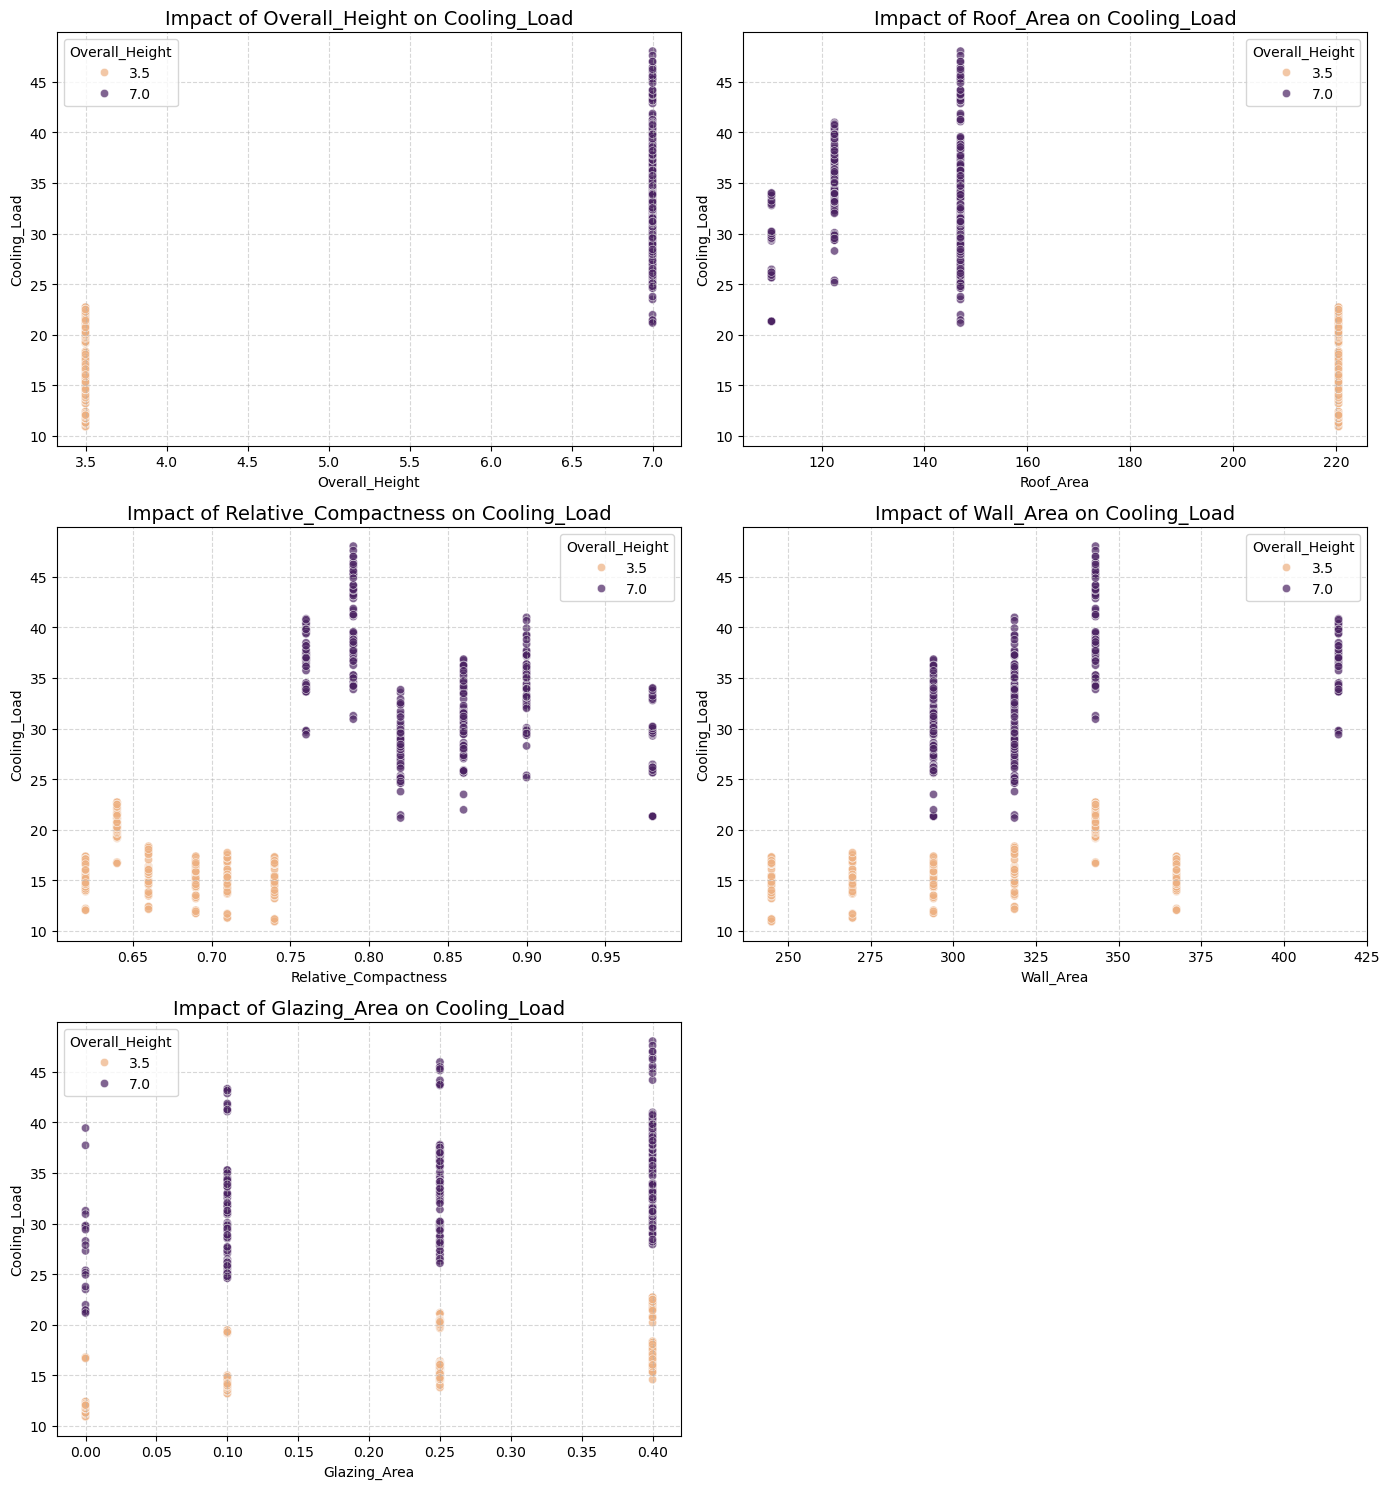

In [14]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

pairs_cooling = [
    ('Overall_Height', 'Cooling_Load'),       
    ('Roof_Area', 'Cooling_Load'),                  
    ('Relative_Compactness', 'Cooling_Load'), 
    ('Wall_Area', 'Cooling_Load'),            
    ('Glazing_Area', 'Cooling_Load')          
]

rows = math.ceil(len(pairs_cooling) / 2)
cols = 2

plt.figure(figsize=(14, 5 * rows))

for i, (x, y) in enumerate(pairs_cooling, 1):
    plt.subplot(rows, cols, i)
    sns.scatterplot(data=df, x=x, y=y, hue='Overall_Height', palette='flare', alpha=0.7)
    plt.title(f"Impact of {x} on {y}", fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Pairplots

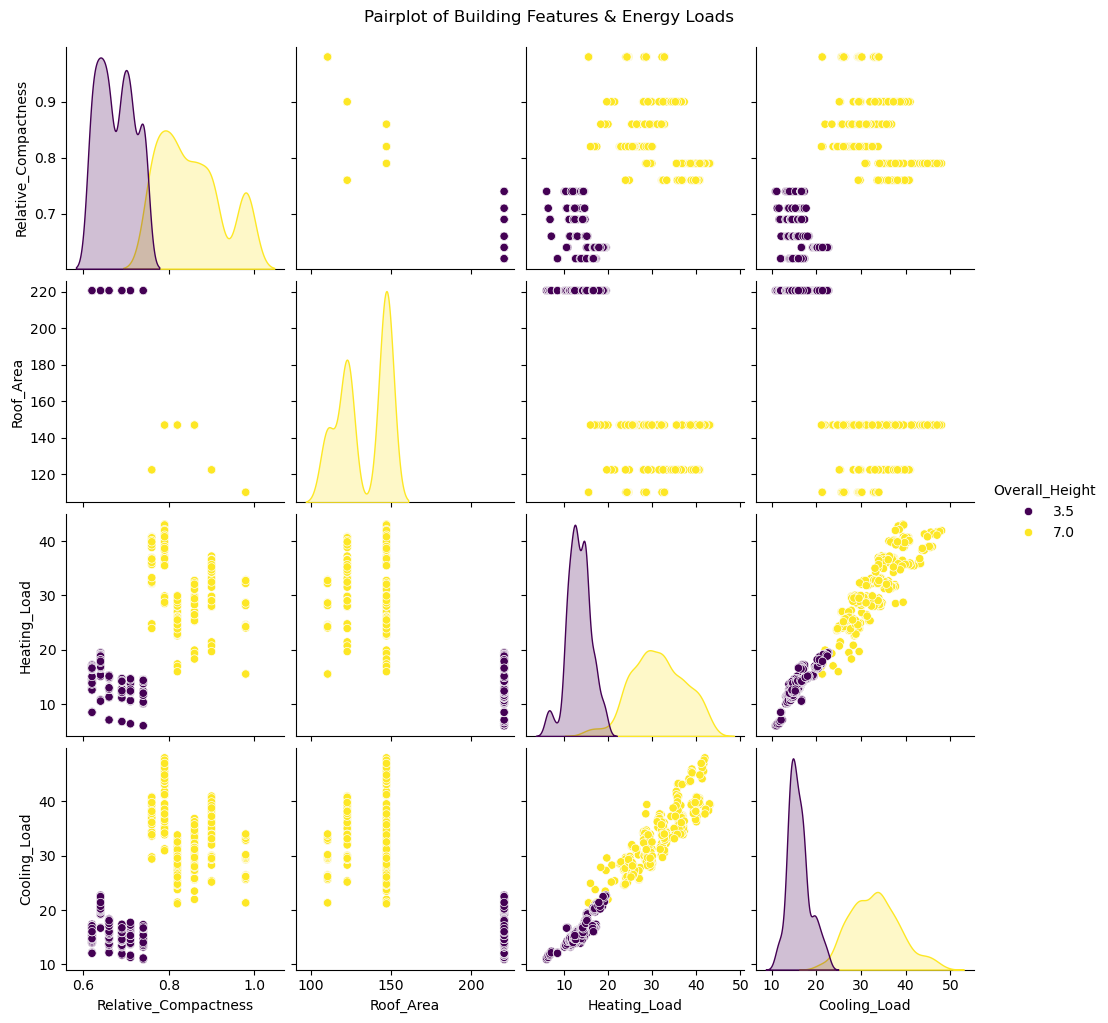

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

selected_cols = [
    'Relative_Compactness', 
    'Overall_Height', 
    'Roof_Area', 
    'Heating_Load', 
    'Cooling_Load'
]

sns.pairplot(df[selected_cols], hue='Overall_Height', palette='viridis')

plt.suptitle("Pairplot of Building Features & Energy Loads", y=1.02)
plt.show()

# Model target variables

In [16]:
# Separate Features into Continuous and Categorical
continuous_cols = ['Relative_Compactness', 'Wall_Area', 'Roof_Area', 'Overall_Height', 'Glazing_Area']
categorical_cols = [col for col in df.columns if col not in continuous_cols + ['Heating_Load', 'Cooling_Load']]
full_feature_names = continuous_cols + categorical_cols

X_base = df[full_feature_names]
y_heating = df['Heating_Load']
y_cooling = df['Cooling_Load']
y_both = df[['Heating_Load', 'Cooling_Load']]

sns.set_theme(style="whitegrid")
shap.initjs()

# PCA Graphs

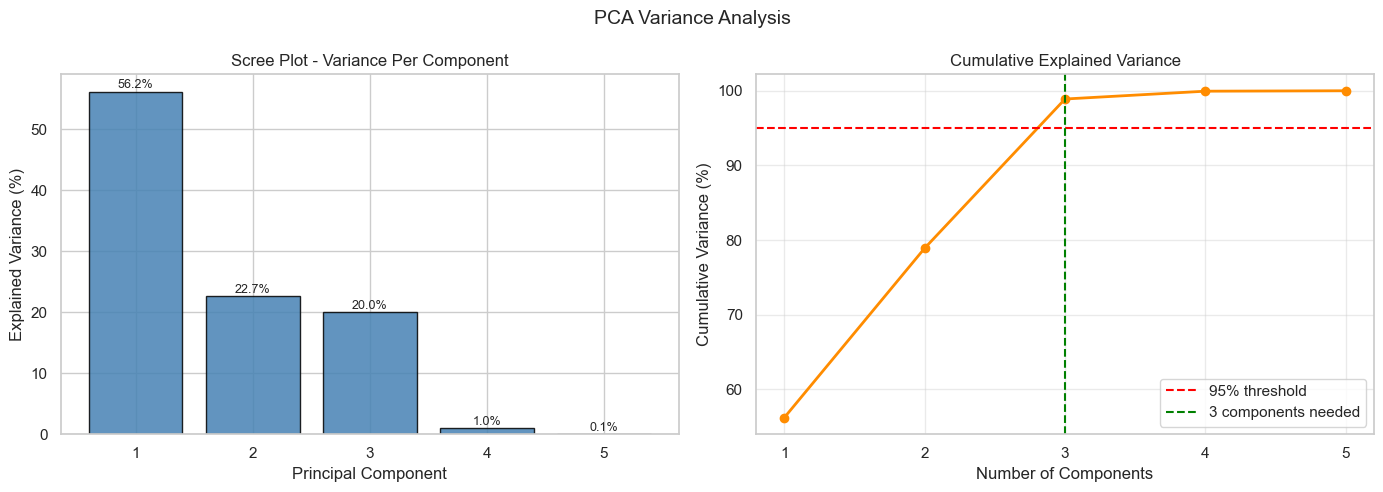

3 components explain 95% of the variance
This means we can reduce 5 features to 3 without losing much information


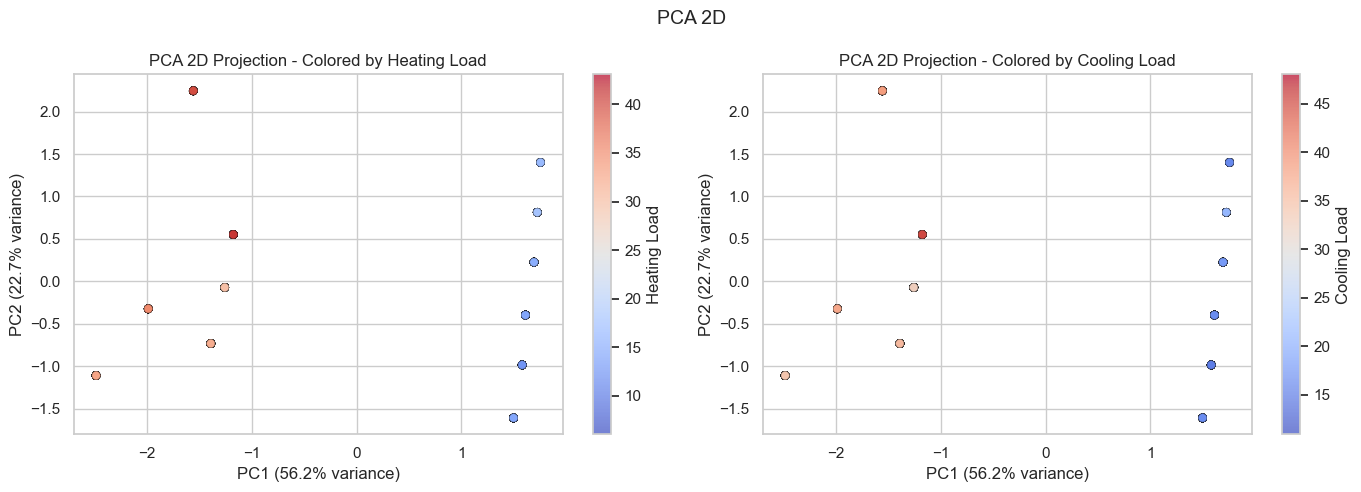

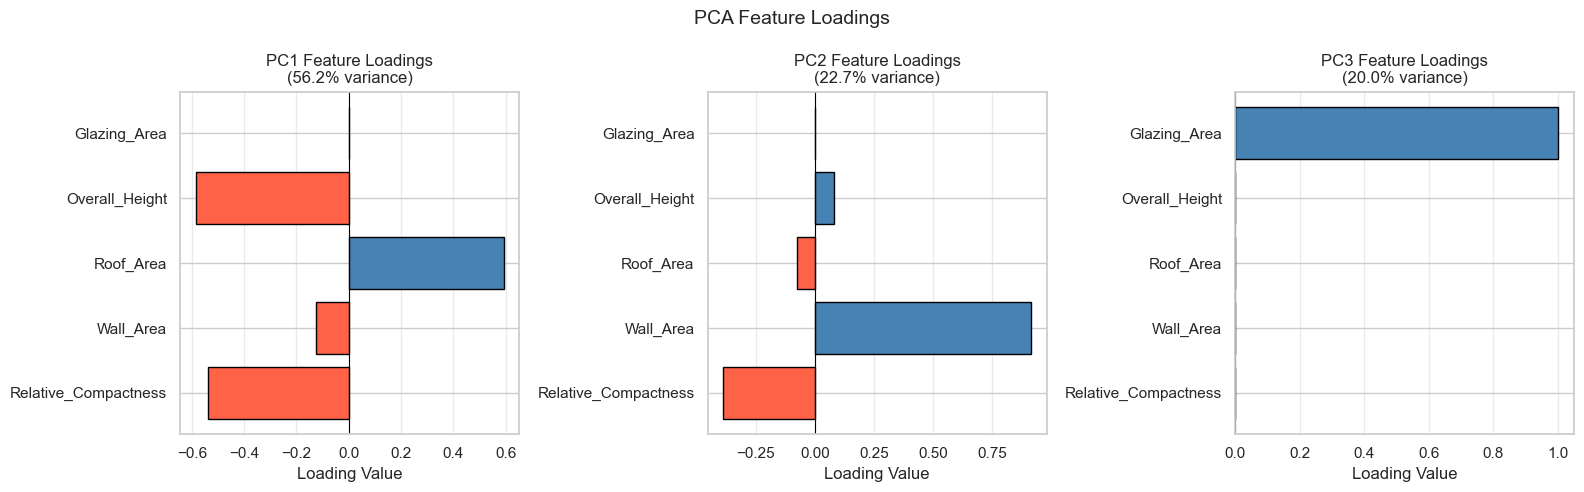


 Feature Loadings
                        PC1    PC2  PC3
Relative_Compactness -0.538 -0.387 -0.0
Wall_Area            -0.126  0.915  0.0
Roof_Area             0.593 -0.077 -0.0
Overall_Height       -0.585  0.082  0.0
Glazing_Area         -0.000 -0.000  1.0


In [63]:
scaler_pca = StandardScaler()
X_pca_data = scaler_pca.fit_transform(df[continuous_cols])

pca_full = PCA(random_state=42)
pca_full.fit(X_pca_data)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
n_components_95 = np.argmax(cumulative >= 0.95) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(explained) + 1), explained * 100,
            color='steelblue', edgecolor='black', alpha=0.85)
axes[0].set_title('Scree Plot - Variance Per Component')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_xticks(range(1, len(explained) + 1))
for i, v in enumerate(explained):
    axes[0].text(i + 1, v * 100 + 0.5, f'{v*100:.1f}%', ha='center', fontsize=9)

axes[1].plot(range(1, len(cumulative) + 1), cumulative * 100,
             marker='o', color='darkorange', linewidth=2)
axes[1].axhline(y=95, color='red', linestyle='--', label='95% threshold')
axes[1].axvline(x=n_components_95, color='green', linestyle='--',
                label=f'{n_components_95} components needed')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].set_xticks(range(1, len(cumulative) + 1))
axes[1].legend()
axes[1].grid(True, alpha=0.4)

plt.suptitle('PCA Variance Analysis', fontsize=14)
plt.tight_layout()
plt.show()

print(f"{n_components_95} components explain 95% of the variance")
print(f"This means we can reduce {len(continuous_cols)} features to {n_components_95} without losing much information")

pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_pca_data)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc1 = axes[0].scatter(X_2d[:, 0], X_2d[:, 1],
                       c=df['Heating_Load'], cmap='coolwarm',
                       alpha=0.7, edgecolors='k', linewidths=0.2)
plt.colorbar(sc1, ax=axes[0], label='Heating Load')
axes[0].set_title('PCA 2D Projection - Colored by Heating Load')
axes[0].set_xlabel(f'PC1 ({explained[0]*100:.1f}% variance)')
axes[0].set_ylabel(f'PC2 ({explained[1]*100:.1f}% variance)')

sc2 = axes[1].scatter(X_2d[:, 0], X_2d[:, 1],
                       c=df['Cooling_Load'], cmap='coolwarm',
                       alpha=0.7, edgecolors='k', linewidths=0.2)
plt.colorbar(sc2, ax=axes[1], label='Cooling Load')
axes[1].set_title('PCA 2D Projection - Colored by Cooling Load')
axes[1].set_xlabel(f'PC1 ({explained[0]*100:.1f}% variance)')
axes[1].set_ylabel(f'PC2 ({explained[1]*100:.1f}% variance)')

plt.suptitle('PCA 2D', fontsize=14)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(
    pca_full.components_[:3].T,
    index=continuous_cols,
    columns=['PC1', 'PC2', 'PC3']
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, pc in enumerate(['PC1', 'PC2', 'PC3']):
    colors_bar = ['steelblue' if v >= 0 else 'tomato' for v in loadings[pc]]
    axes[i].barh(loadings.index, loadings[pc], color=colors_bar, edgecolor='black')
    axes[i].axvline(x=0, color='black', linewidth=0.8)
    axes[i].set_title(f'{pc} Feature Loadings\n({explained[i]*100:.1f}% variance)')
    axes[i].set_xlabel('Loading Value')
    axes[i].grid(axis='x', alpha=0.4)

plt.suptitle('PCA Feature Loadings', fontsize=14)
plt.tight_layout()
plt.show()

print("\n Feature Loadings")
print(loadings.round(3))


# Clustering

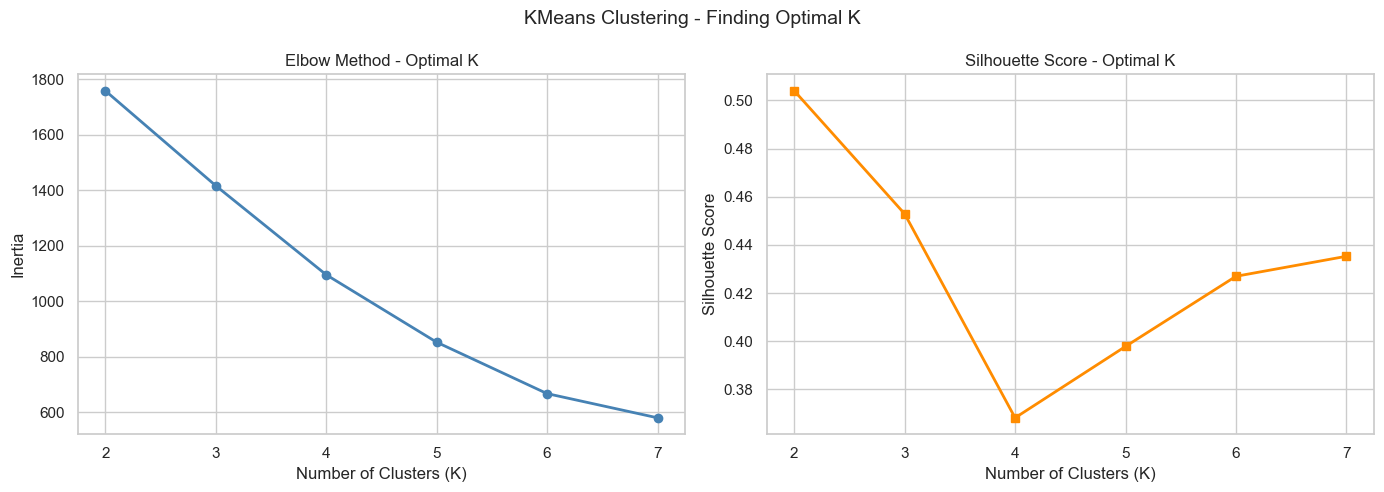

Best K based on Silhouette Score: 2


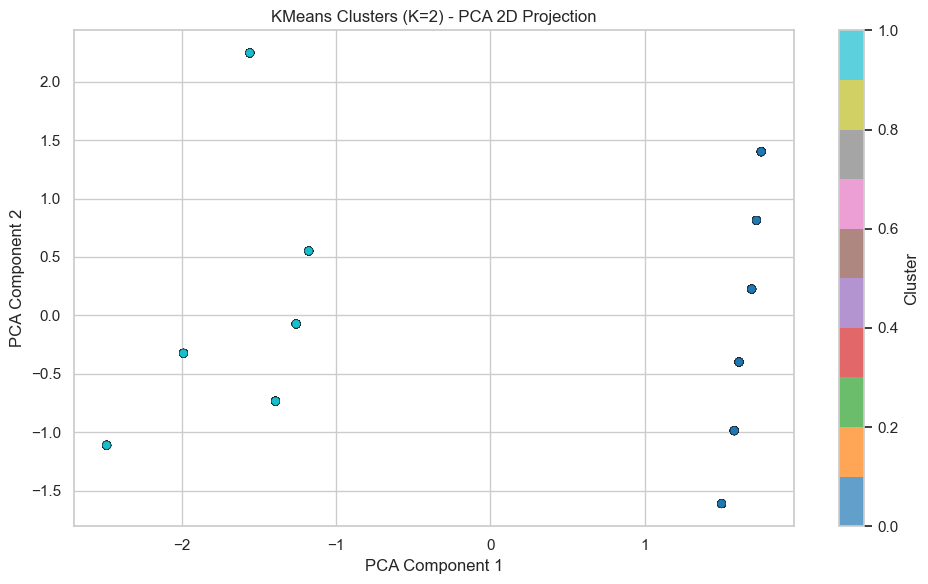


Cluster Profiles (mean values per cluster):
         Relative_Compactness  Wall_Area  Roof_Area  Overall_Height  \
Cluster                                                               
0                        0.68     306.25     220.50             3.5   
1                        0.85     330.75     132.71             7.0   

         Glazing_Area  Heating_Load  Cooling_Load  
Cluster                                            
0                0.23         13.34         16.07  
1                0.23         31.28         33.10  


In [ ]:
X_cluster = df[continuous_cols].copy()
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

inertias = []
silhouettes = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbs = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster_scaled, lbs))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, marker='o', color='steelblue', linewidth=2)
axes[0].set_title('Elbow Method - Optimal K')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

axes[1].plot(K_range, silhouettes, marker='s', color='darkorange', linewidth=2)
axes[1].set_title('Silhouette Score - Optimal K')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

plt.suptitle('KMeans Clustering - Finding Optimal K', fontsize=14)
plt.tight_layout()
plt.show()


best_k = K_range[silhouettes.index(max(silhouettes))]
print(f"Best K based on Silhouette Score: {best_k}")

km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = km_final.fit_predict(X_cluster_scaled)

pca_viz = PCA(n_components=2, random_state=42)
X_pca_2d = pca_viz.fit_transform(X_cluster_scaled)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1],
                      c=df['Cluster'], cmap='tab10',
                      alpha=0.7, edgecolors='k', linewidths=0.3)
plt.colorbar(scatter, label='Cluster')
plt.title(f'KMeans Clusters (K={best_k}) - PCA 2D Projection')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.tight_layout()
plt.show()

cluster_profile = df.groupby('Cluster')[continuous_cols + ['Heating_Load', 'Cooling_Load']].mean().round(2)
print("\nCluster Profiles (mean values per cluster):")
print(cluster_profile)

df.drop(columns=['Cluster'], inplace=True)

# XGBoost (Heating Load)

Overfitting Check
Train R2: 0.9998 | MAE: 0.0917
Test  R2: 0.9984 | MAE: 0.2936
Gap (Train - Test): 0.0014

Best Params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 500}

Final Test Evaluation
[XGBoost - Heating] Base R2: 0.9984 | MAE: 0.2936 | MSE: 0.1667


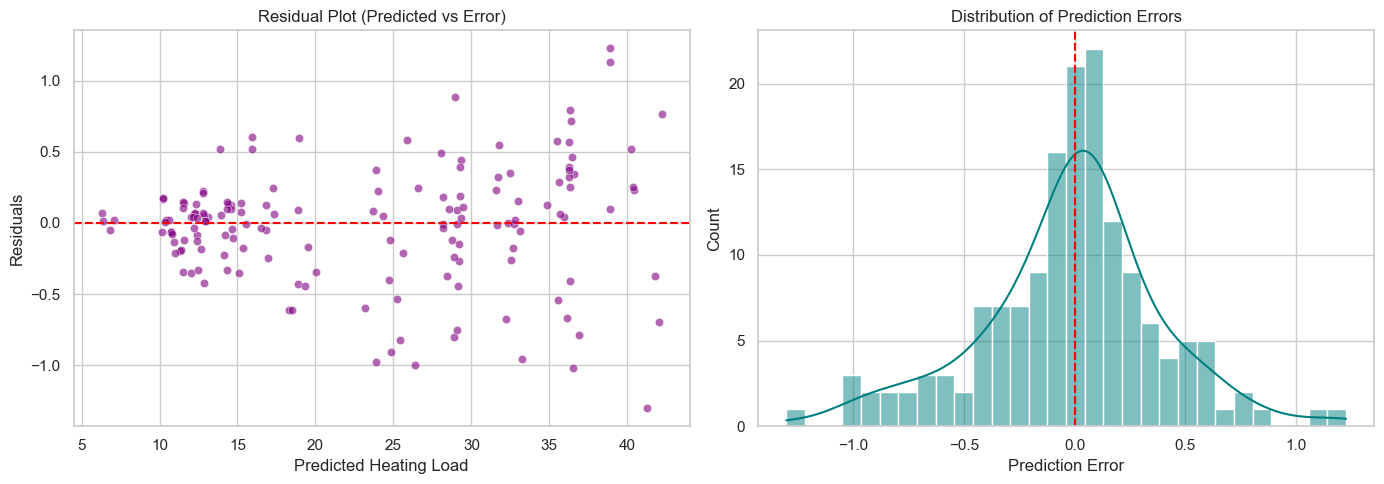

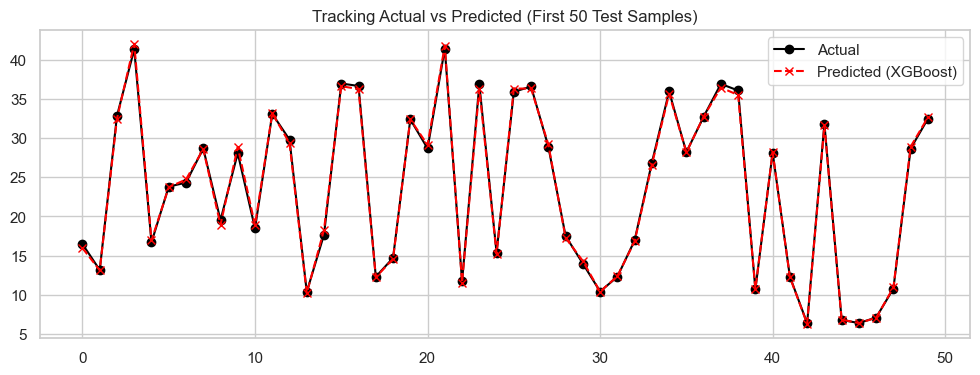

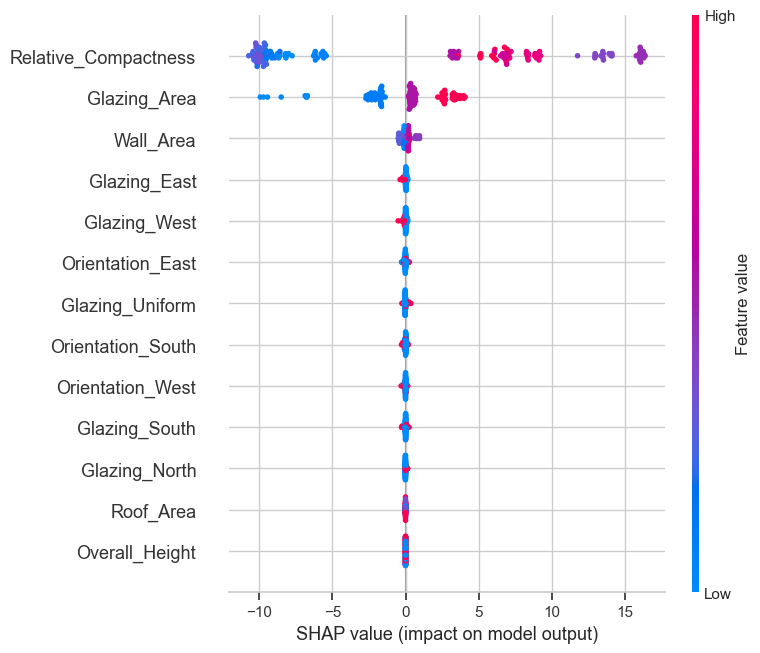

<Figure size 800x500 with 0 Axes>

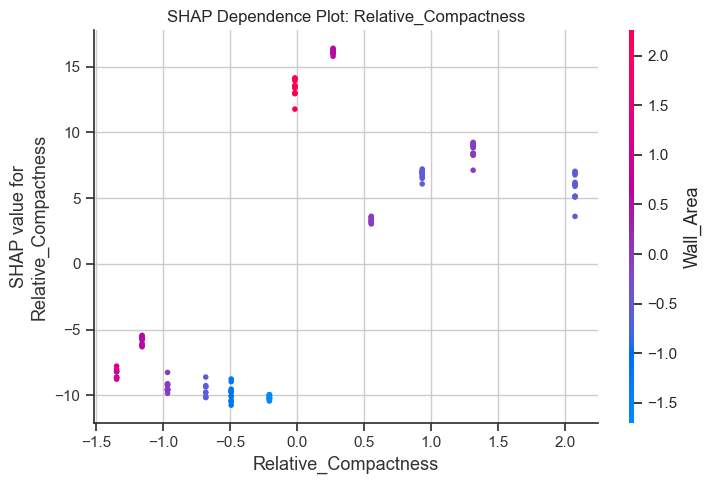

Top 2 Features Identified: ['Relative_Compactness', 'Glazing_Area']
[XGBoost - Heating] Top 2 R2: 0.9976 | MAE: 0.3729 | MSE: 0.2519


In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_base, y_heating, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_val_cont_scaled = scaler.fit_transform(X_train_val[continuous_cols])
X_test_cont_scaled = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_val_pca_cont = pca.fit_transform(X_train_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_val_combined = np.hstack([X_train_val_pca_cont, X_train_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_val_full_scaled = np.hstack([X_train_val_cont_scaled, X_train_val[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
xgb_params = {'n_estimators': [100, 500], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]}
xgb_grid = GridSearchCV(xgb_model, xgb_params, cv=5, scoring='neg_mean_squared_error')
xgb_grid.fit(X_train_val_combined, y_train_val)
xgb_preds = xgb_grid.predict(X_test_combined)

xgb_train_preds = xgb_grid.predict(X_train_val_combined)
print("Overfitting Check")
print(f"Train R2: {r2_score(y_train_val, xgb_train_preds):.4f} | MAE: {mean_absolute_error(y_train_val, xgb_train_preds):.4f}")
print(f"Test  R2: {r2_score(y_test, xgb_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_preds):.4f}")
print(f"Gap (Train - Test): {r2_score(y_train_val, xgb_train_preds) - r2_score(y_test, xgb_preds):.4f}")
print()
print(f"Best Params: {xgb_grid.best_params_}")
print()

print("Final Test Evaluation")
print(f"[XGBoost - Heating] Base R2: {r2_score(y_test, xgb_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_preds):.4f} | MSE: {mean_squared_error(y_test, xgb_preds):.4f}")

residuals = y_test - xgb_preds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=xgb_preds, y=residuals, color='purple', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Predicted vs Error)')
axes[0].set_xlabel('Predicted Heating Load')
axes[0].set_ylabel('Residuals')

sns.histplot(residuals, bins=30, kde=True, color='teal', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_title('Distribution of Prediction Errors')
axes[1].set_xlabel('Prediction Error')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(50), y_test.values[:50], label='Actual', marker='o', color='black')
plt.plot(range(50), xgb_preds[:50], label='Predicted (XGBoost)', marker='x', color='red', linestyle='--')
plt.title('Tracking Actual vs Predicted (First 50 Test Samples)')
plt.legend()
plt.show()

xgb_shap_model = xgb.XGBRegressor(**xgb_grid.best_params_, random_state=42).fit(X_train_val_full_scaled, y_train_val)
explainer = shap.TreeExplainer(xgb_shap_model)
shap_values = explainer.shap_values(X_test_full_scaled)

plt.figure(figsize=(8, 5))
plt.title("SHAP Summary: XGBoost (Heating)")
shap.summary_plot(shap_values, X_test_full_scaled, feature_names=full_feature_names)

fi = np.abs(shap_values).mean(axis=0)
top_2_indices = np.argsort(fi)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]

plt.figure(figsize=(8, 5))
shap.dependence_plot(top_2_features[0], shap_values, X_test_full_scaled, feature_names=full_feature_names, show=False)
plt.title(f'SHAP Dependence Plot: {top_2_features[0]}')
plt.tight_layout()
plt.show()

print(f"Top 2 Features Identified: {top_2_features}")
scaler_top2 = StandardScaler()
X_train_val_top2 = scaler_top2.fit_transform(X_train_val[top_2_features])
X_test_top2 = scaler_top2.transform(X_test[top_2_features])

xgb_top2 = xgb.XGBRegressor(**xgb_grid.best_params_, random_state=42).fit(X_train_val_top2, y_train_val)
xgb_top2_preds = xgb_top2.predict(X_test_top2)
print(f"[XGBoost - Heating] Top 2 R2: {r2_score(y_test, xgb_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_top2_preds):.4f} | MSE: {mean_squared_error(y_test, xgb_top2_preds):.4f}")

xgb_heat_r2 = r2_score(y_test, xgb_preds)
xgb_heat_mae = mean_absolute_error(y_test, xgb_preds)
xgb_heat_mse = mean_squared_error(y_test, xgb_preds)

# XGBoost (Cooling Load)

Overfitting Check
Train R2: 0.9986 | MAE: 0.2503
Test  R2: 0.9704 | MAE: 0.9920
Gap (Train - Test): 0.0281

Best Params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 500}

Final Test Evaluation
[XGBoost - Cooling] Base R2: 0.9704 | MAE: 0.9920 | MSE: 2.7393


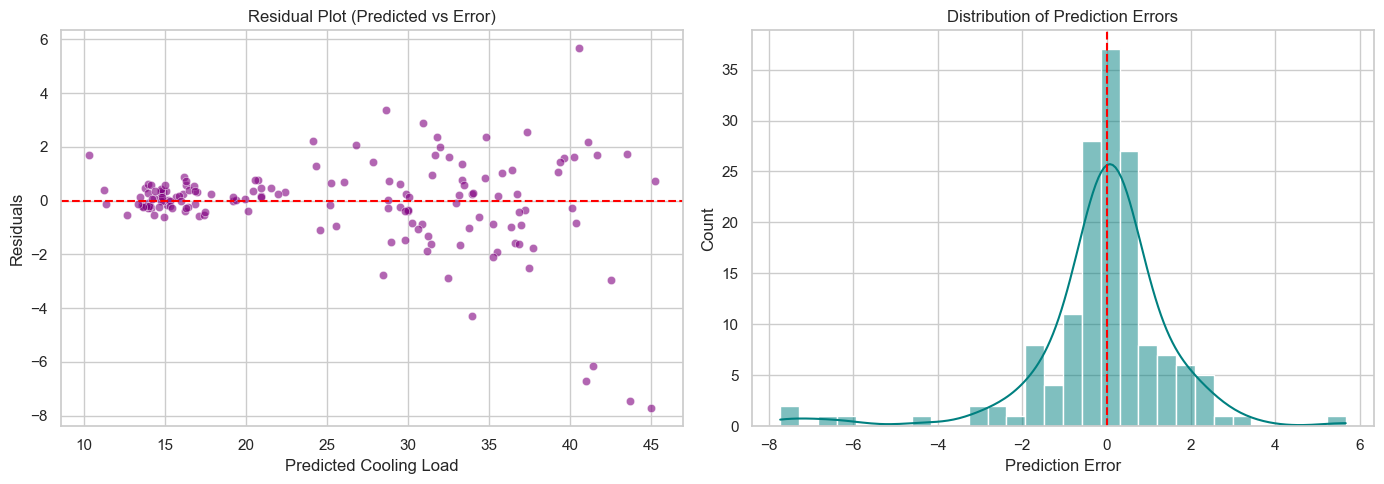

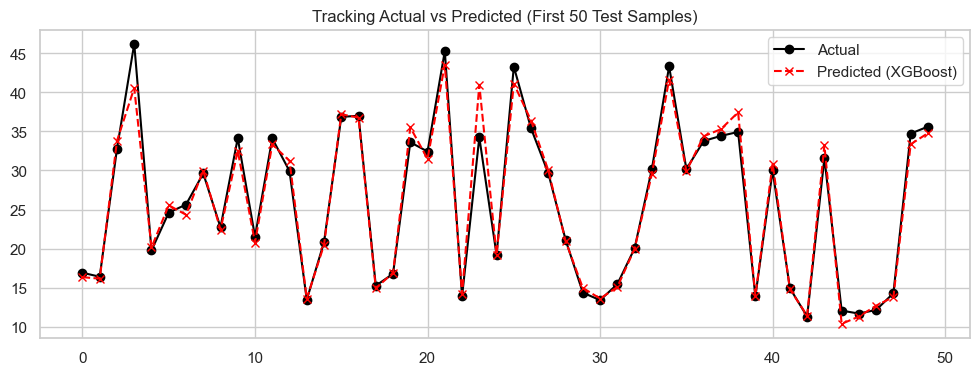

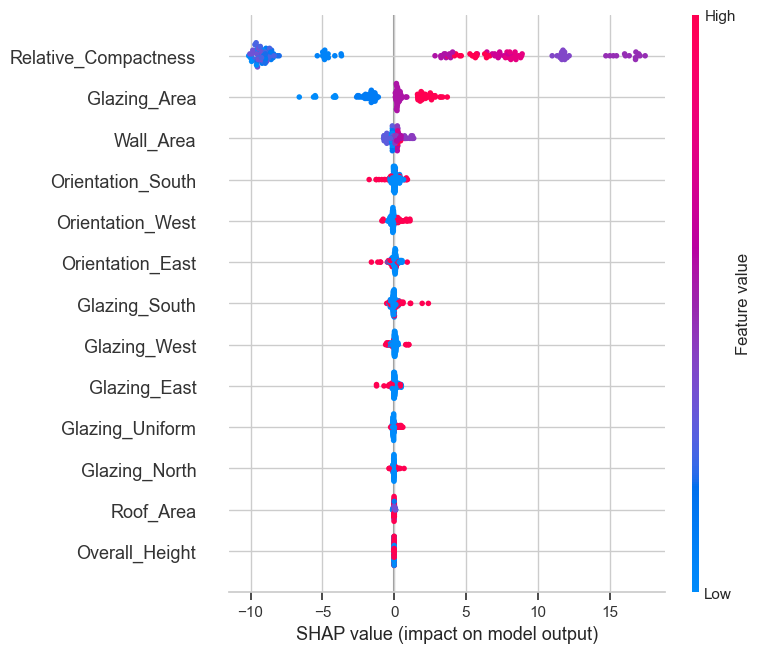

<Figure size 800x500 with 0 Axes>

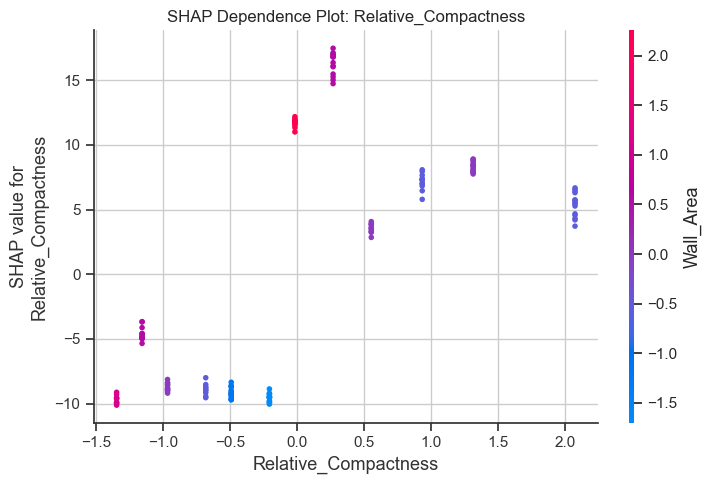

Top 2 Features Identified: ['Relative_Compactness', 'Glazing_Area']
[XGBoost - Cooling] Top 2 R2: 0.9670 | MAE: 1.1649 | MSE: 3.0555


In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_base, y_cooling, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_val_cont_scaled = scaler.fit_transform(X_train_val[continuous_cols])
X_test_cont_scaled = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_val_pca_cont = pca.fit_transform(X_train_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_val_combined = np.hstack([X_train_val_pca_cont, X_train_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_val_full_scaled = np.hstack([X_train_val_cont_scaled, X_train_val[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
xgb_params = {'n_estimators': [100, 500], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]}
xgb_grid = GridSearchCV(xgb_model, xgb_params, cv=5, scoring='neg_mean_squared_error')
xgb_grid.fit(X_train_val_combined, y_train_val)
xgb_preds = xgb_grid.predict(X_test_combined)

xgb_train_preds = xgb_grid.predict(X_train_val_combined)
print("Overfitting Check")
print(f"Train R2: {r2_score(y_train_val, xgb_train_preds):.4f} | MAE: {mean_absolute_error(y_train_val, xgb_train_preds):.4f}")
print(f"Test  R2: {r2_score(y_test, xgb_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_preds):.4f}")
print(f"Gap (Train - Test): {r2_score(y_train_val, xgb_train_preds) - r2_score(y_test, xgb_preds):.4f}")
print()
print(f"Best Params: {xgb_grid.best_params_}")
print()

print("Final Test Evaluation")
print(f"[XGBoost - Cooling] Base R2: {r2_score(y_test, xgb_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_preds):.4f} | MSE: {mean_squared_error(y_test, xgb_preds):.4f}")

residuals = y_test - xgb_preds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=xgb_preds, y=residuals, color='purple', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Predicted vs Error)')
axes[0].set_xlabel('Predicted Cooling Load')
axes[0].set_ylabel('Residuals')

sns.histplot(residuals, bins=30, kde=True, color='teal', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_title('Distribution of Prediction Errors')
axes[1].set_xlabel('Prediction Error')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(50), y_test.values[:50], label='Actual', marker='o', color='black')
plt.plot(range(50), xgb_preds[:50], label='Predicted (XGBoost)', marker='x', color='red', linestyle='--')
plt.title('Tracking Actual vs Predicted (First 50 Test Samples)')
plt.legend()
plt.show()

xgb_shap_model = xgb.XGBRegressor(**xgb_grid.best_params_, random_state=42).fit(X_train_val_full_scaled, y_train_val)
explainer = shap.TreeExplainer(xgb_shap_model)
shap_values = explainer.shap_values(X_test_full_scaled)

plt.figure(figsize=(8, 5))
plt.title("SHAP Summary: XGBoost (Cooling)")
shap.summary_plot(shap_values, X_test_full_scaled, feature_names=full_feature_names)

fi = np.abs(shap_values).mean(axis=0)
top_2_indices = np.argsort(fi)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]

plt.figure(figsize=(8, 5))
shap.dependence_plot(top_2_features[0], shap_values, X_test_full_scaled, feature_names=full_feature_names, show=False)
plt.title(f'SHAP Dependence Plot: {top_2_features[0]}')
plt.tight_layout()
plt.show()

print(f"Top 2 Features Identified: {top_2_features}")
scaler_top2 = StandardScaler()
X_train_val_top2 = scaler_top2.fit_transform(X_train_val[top_2_features])
X_test_top2 = scaler_top2.transform(X_test[top_2_features])

xgb_top2 = xgb.XGBRegressor(**xgb_grid.best_params_, random_state=42).fit(X_train_val_top2, y_train_val)
xgb_top2_preds = xgb_top2.predict(X_test_top2)
print(f"[XGBoost - Cooling] Top 2 R2: {r2_score(y_test, xgb_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_top2_preds):.4f} | MSE: {mean_squared_error(y_test, xgb_top2_preds):.4f}")

xgb_cool_r2 = r2_score(y_test, xgb_preds)
xgb_cool_mae = mean_absolute_error(y_test, xgb_preds)
xgb_cool_mse = mean_squared_error(y_test, xgb_preds)

# XGBoost (Both Target Variables)

Overfitting Check
Train R2: 0.9992 | MAE: 0.1710
Test  R2: 0.9844 | MAE: 0.6428
Gap (Train - Test): 0.0148

Best Params: {'estimator__learning_rate': 0.05, 'estimator__max_depth': 5, 'estimator__n_estimators': 500}

Final Test Evaluation
[XGBoost - Both] Base R2: 0.9844 | MAE: 0.6428 | MSE: 1.4530


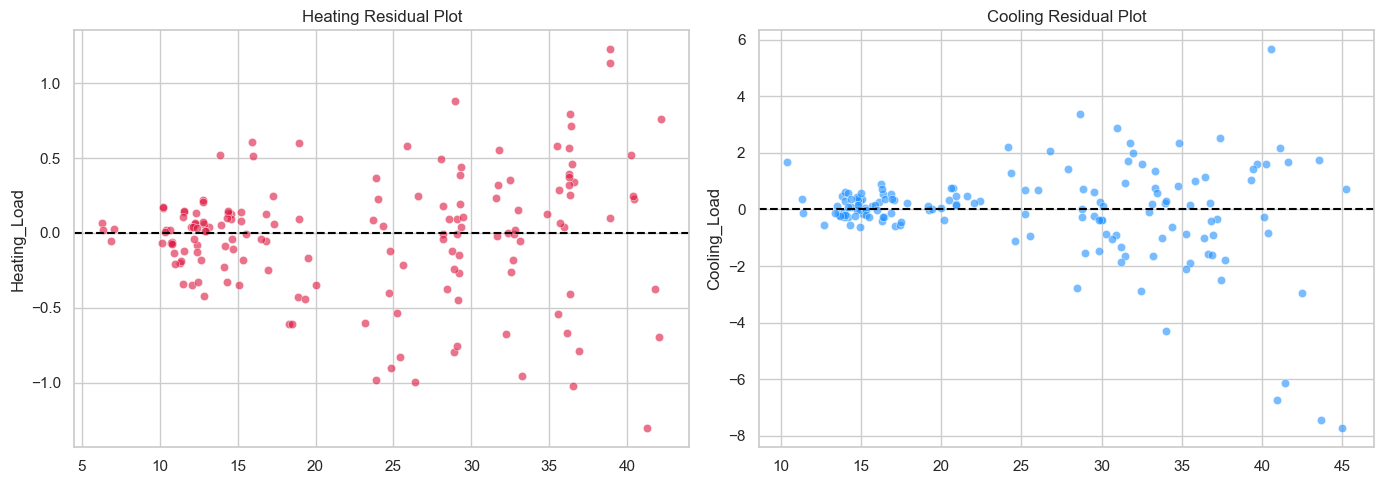

Top 2 Features Identified (Averaged): ['Relative_Compactness', 'Glazing_Area']
[XGBoost - Both] Top 2 R2: 0.9823 | MAE: 0.7689 | MSE: 1.6537


In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_base, y_both, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_val_cont_scaled = scaler.fit_transform(X_train_val[continuous_cols])
X_test_cont_scale = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_val_pca_cont = pca.fit_transform(X_train_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_val_combined = np.hstack([X_train_val_pca_cont, X_train_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_val_full_scaled = np.hstack([X_train_val_cont_scaled, X_train_val[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

xgb_base = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)
multi_xgb = MultiOutputRegressor(xgb_base)
xgb_params = {'estimator__n_estimators': [100, 500], 'estimator__learning_rate': [0.05, 0.1], 'estimator__max_depth': [3, 5]}
xgb_grid = GridSearchCV(multi_xgb, xgb_params, cv=5, scoring='neg_mean_squared_error')
xgb_grid.fit(X_train_val_combined, y_train_val)
xgb_preds = xgb_grid.predict(X_test_combined)

xgb_train_preds = xgb_grid.predict(X_train_val_combined)
print("Overfitting Check")
print(f"Train R2: {r2_score(y_train_val, xgb_train_preds):.4f} | MAE: {mean_absolute_error(y_train_val, xgb_train_preds):.4f}")
print(f"Test  R2: {r2_score(y_test, xgb_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_preds):.4f}")
print(f"Gap (Train - Test): {r2_score(y_train_val, xgb_train_preds) - r2_score(y_test, xgb_preds):.4f}")
print()
print(f"Best Params: {xgb_grid.best_params_}")
print()

print("Final Test Evaluation")
print(f"[XGBoost - Both] Base R2: {r2_score(y_test, xgb_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_preds):.4f} | MSE: {mean_squared_error(y_test, xgb_preds):.4f}")

res_heat = y_test['Heating_Load'] - xgb_preds[:, 0]
res_cool = y_test['Cooling_Load']  - xgb_preds[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=xgb_preds[:, 0], y=res_heat, color='crimson', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='black', linestyle='--')
axes[0].set_title('Heating Residual Plot')

sns.scatterplot(x=xgb_preds[:, 1], y=res_cool, color='dodgerblue', alpha=0.6, ax=axes[1])
axes[1].axhline(y=0, color='black', linestyle='--')
axes[1].set_title('Cooling Residual Plot')
plt.tight_layout()
plt.show()

multi_shap = MultiOutputRegressor(xgb.XGBRegressor(
    n_estimators=xgb_grid.best_params_['estimator__n_estimators'],
    learning_rate=xgb_grid.best_params_['estimator__learning_rate'],
    max_depth=xgb_grid.best_params_['estimator__max_depth'], random_state=42
)).fit(X_train_val_full_scaled, y_train_val)

explainer_heat = shap.TreeExplainer(multi_shap.estimators_[0])
explainer_cool = shap.TreeExplainer(multi_shap.estimators_[1])

shap_heat = np.abs(explainer_heat.shap_values(X_test_full_scaled)).mean(axis=0)
shap_cool = np.abs(explainer_cool.shap_values(X_test_full_scaled)).mean(axis=0)
fi_global = (shap_heat + shap_cool) / 2

top_2_indices = np.argsort(fi_global)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]
print(f"Top 2 Features Identified (Averaged): {top_2_features}")

scaler_top2 = StandardScaler()
X_train_val_top2 = scaler_top2.fit_transform(X_train_val[top_2_features])
X_test_top2 = scaler_top2.transform(X_test[top_2_features])

xgb_top2 = MultiOutputRegressor(xgb.XGBRegressor(
    n_estimators=xgb_grid.best_params_['estimator__n_estimators'],
    learning_rate=xgb_grid.best_params_['estimator__learning_rate'],
    max_depth=xgb_grid.best_params_['estimator__max_depth'], random_state=42
)).fit(X_train_val_top2, y_train_val)
xgb_top2_preds = xgb_top2.predict(X_test_top2)
print(f"[XGBoost - Both] Top 2 R2: {r2_score(y_test, xgb_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, xgb_top2_preds):.4f} | MSE: {mean_squared_error(y_test, xgb_top2_preds):.4f}")

xgb_both_r2 = r2_score(y_test, xgb_preds)
xgb_both_mae = mean_absolute_error(y_test, xgb_preds)
xgb_both_mse = mean_squared_error(y_test, xgb_preds)

# KNN (Heating Load)

Overfitting Check
Train R2: 0.9396 | MAE: 1.6324
Test  R2: 0.9123 | MAE: 1.9603
Gap (Train - Test): 0.0273

Best Params: {'n_neighbors': 11, 'weights': 'uniform'}

Final Test Evaluation
[KNN - Heating] Base R2: 0.9123 | MAE: 1.9603 | MSE: 9.1433


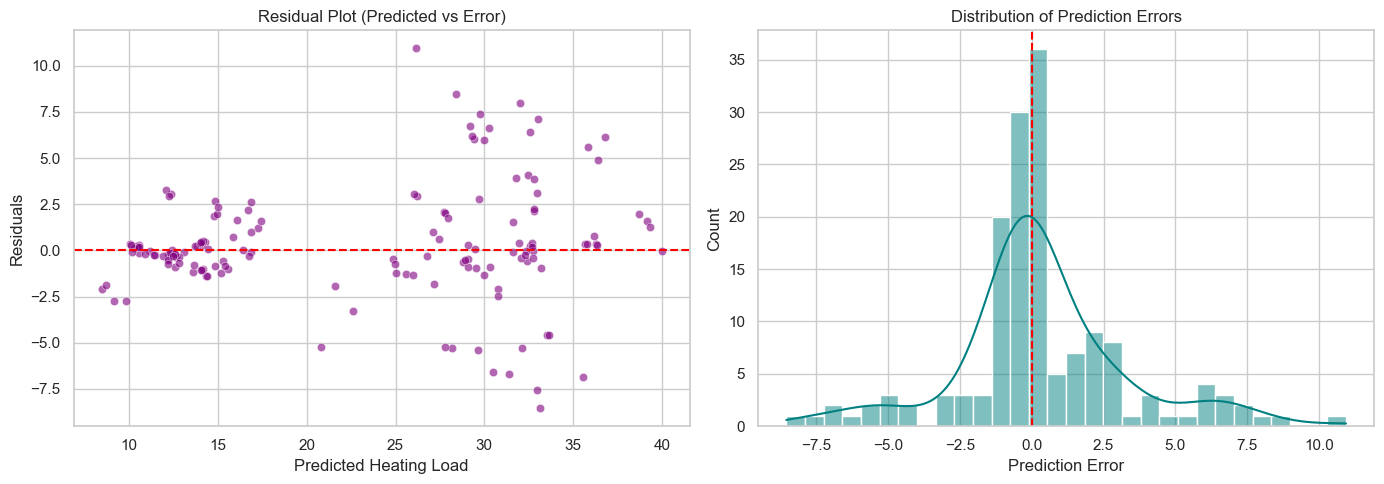

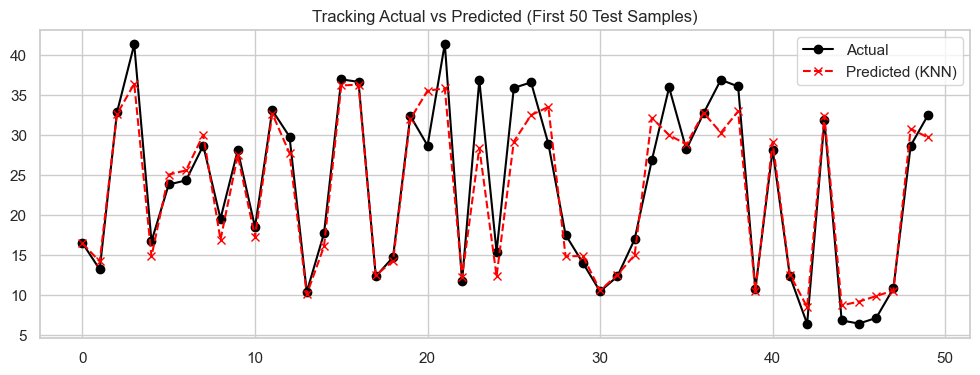

100%|██████████| 154/154 [03:32<00:00,  1.38s/it]


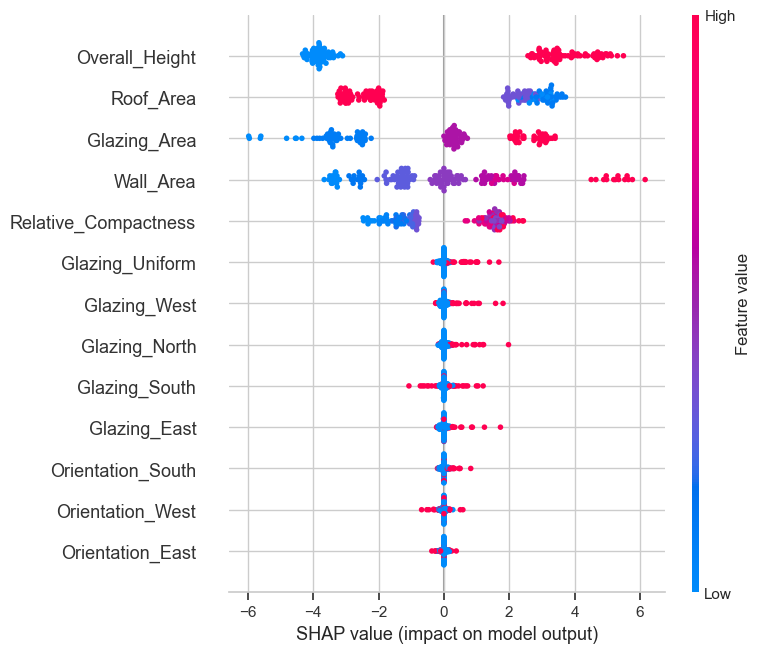

<Figure size 800x500 with 0 Axes>

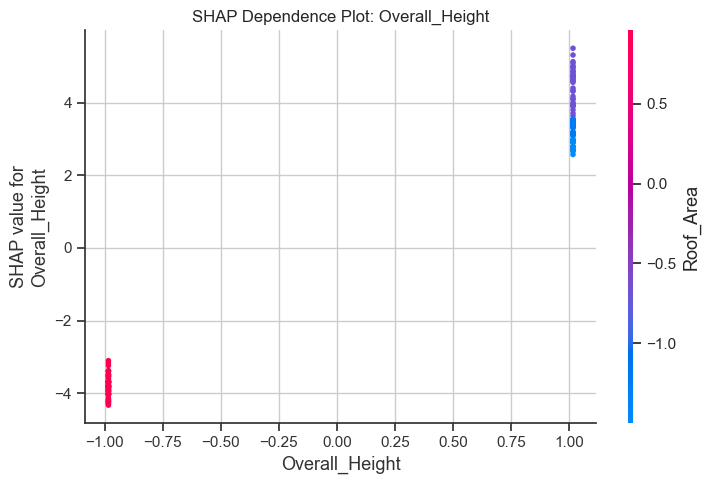

Top 2 Features Identified: ['Overall_Height', 'Roof_Area']
[KNN - Heating] Top 2 R2: 0.8060 | MAE: 3.5578 | MSE: 20.2160


In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_base, y_heating, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_val_cont_scaled = scaler.fit_transform(X_train_val[continuous_cols])
X_test_cont_scaled = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_val_pca_cont = pca.fit_transform(X_train_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_val_combined = np.hstack([X_train_val_pca_cont, X_train_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_val_full_scaled = np.hstack([X_train_val_cont_scaled, X_train_val[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

knn_params = {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance']}
knn_grid = GridSearchCV(KNeighborsRegressor(), knn_params, cv=5, scoring='neg_mean_squared_error')
knn_grid.fit(X_train_val_combined, y_train_val)
knn_preds = knn_grid.predict(X_test_combined)

knn_train_preds = knn_grid.predict(X_train_val_combined)
print("Overfitting Check")
print(f"Train R2: {r2_score(y_train_val, knn_train_preds):.4f} | MAE: {mean_absolute_error(y_train_val, knn_train_preds):.4f}")
print(f"Test  R2: {r2_score(y_test, knn_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_preds):.4f}")
print(f"Gap (Train - Test): {r2_score(y_train_val, knn_train_preds) - r2_score(y_test, knn_preds):.4f}")
print()
print(f"Best Params: {knn_grid.best_params_}")
print()

print("Final Test Evaluation")
print(f"[KNN - Heating] Base R2: {r2_score(y_test, knn_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_preds):.4f} | MSE: {mean_squared_error(y_test, knn_preds):.4f}")

residuals = y_test - knn_preds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=knn_preds, y=residuals, color='purple', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Predicted vs Error)')
axes[0].set_xlabel('Predicted Heating Load')
axes[0].set_ylabel('Residuals')

sns.histplot(residuals, bins=30, kde=True, color='teal', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_title('Distribution of Prediction Errors')
axes[1].set_xlabel('Prediction Error')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(50), y_test.values[:50], label='Actual', marker='o', color='black')
plt.plot(range(50), knn_preds[:50], label='Predicted (KNN)', marker='x', color='red', linestyle='--')
plt.title('Tracking Actual vs Predicted (First 50 Test Samples)')
plt.legend()
plt.show()

knn_shap_model = KNeighborsRegressor(**knn_grid.best_params_).fit(X_train_val_full_scaled, y_train_val)
background = shap.kmeans(X_train_val_full_scaled, 25)
explainer = shap.KernelExplainer(knn_shap_model.predict, background)
shap_values = explainer.shap_values(X_test_full_scaled)

plt.figure(figsize=(8, 5))
plt.title("SHAP Summary: KNN (Heating)")
shap.summary_plot(shap_values, X_test_full_scaled, feature_names=full_feature_names)

fi = np.abs(shap_values).mean(axis=0)
top_2_indices = np.argsort(fi)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]

plt.figure(figsize=(8, 5))
shap.dependence_plot(top_2_features[0], shap_values, X_test_full_scaled, feature_names=full_feature_names, show=False)
plt.title(f'SHAP Dependence Plot: {top_2_features[0]}')
plt.tight_layout()
plt.show()

print(f"Top 2 Features Identified: {top_2_features}")
scaler_top2 = StandardScaler()
X_train_val_top2 = scaler_top2.fit_transform(X_train_val[top_2_features])
X_test_top2 = scaler_top2.transform(X_test[top_2_features])

knn_top2 = KNeighborsRegressor(**knn_grid.best_params_).fit(X_train_val_top2, y_train_val)
knn_top2_preds = knn_top2.predict(X_test_top2)
print(f"[KNN - Heating] Top 2 R2: {r2_score(y_test, knn_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_top2_preds):.4f} | MSE: {mean_squared_error(y_test, knn_top2_preds):.4f}")

knn_heat_r2 = r2_score(y_test, knn_preds)
knn_heat_mae = mean_absolute_error(y_test, knn_preds)
knn_heat_mse = mean_squared_error(y_test, knn_preds)


# KNN (Cooling Load)

Overfitting Check
Train R2: 0.9191 | MAE: 1.8488
Test  R2: 0.9083 | MAE: 1.9642
Gap (Train - Test): 0.0109

Best Params: {'n_neighbors': 11, 'weights': 'uniform'}

Final Test Evaluation
[KNN - Cooling] Base R2: 0.9083 | MAE: 1.9642 | MSE: 8.5011


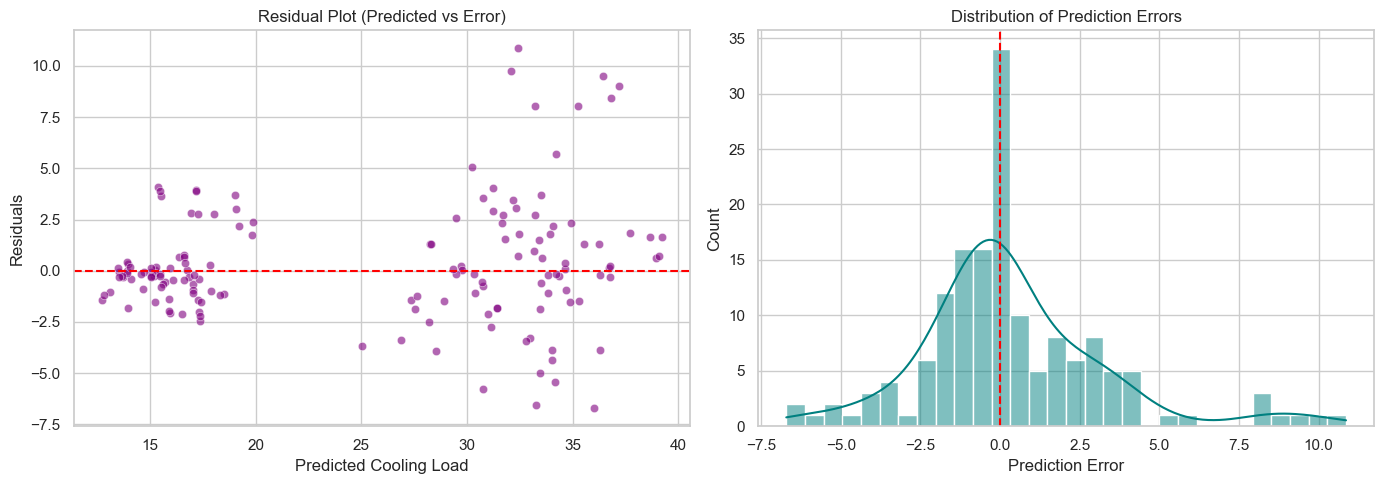

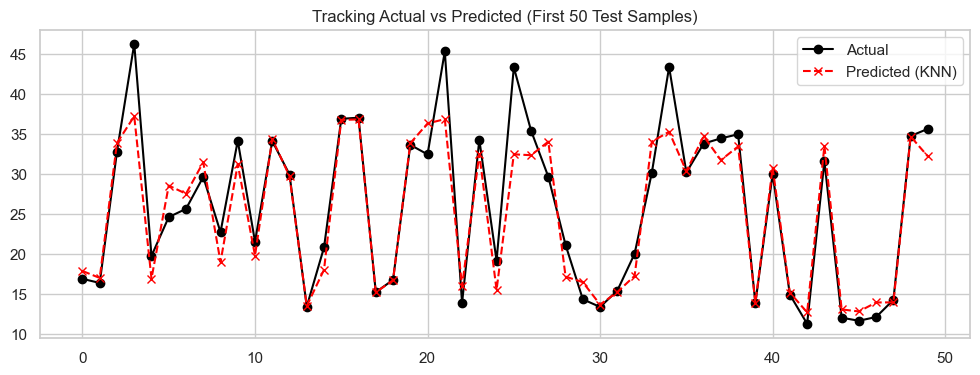

100%|██████████| 154/154 [03:27<00:00,  1.35s/it]


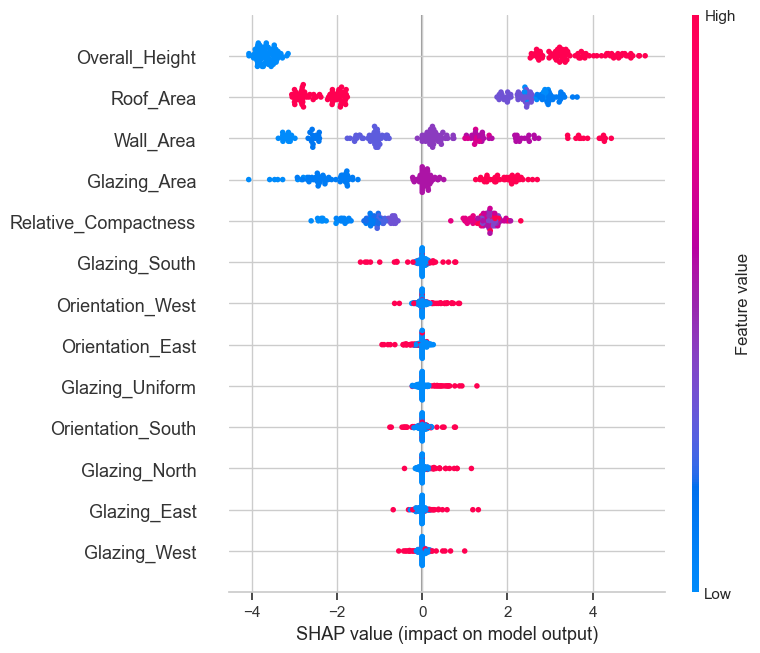

<Figure size 800x500 with 0 Axes>

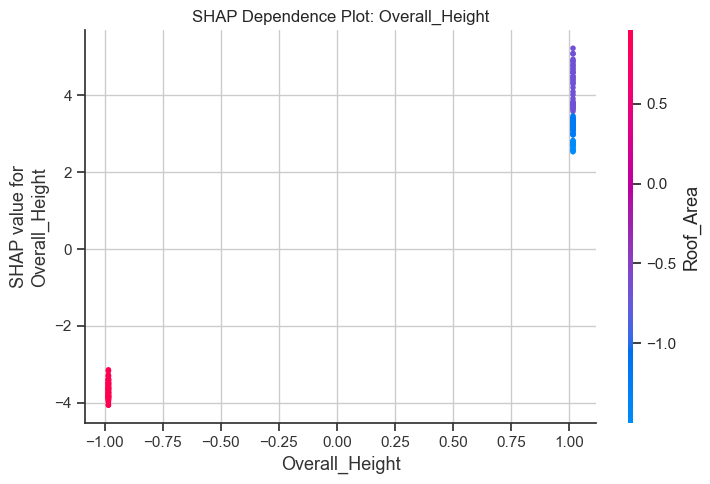

Top 2 Features Identified: ['Overall_Height', 'Roof_Area']
[KNN - Cooling] Top 2 R2: 0.8298 | MAE: 3.0145 | MSE: 15.7681


In [ ]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_base, y_cooling, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_val_cont_scaled = scaler.fit_transform(X_train_val[continuous_cols])
X_test_cont_scaled = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_val_pca_cont = pca.fit_transform(X_train_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_val_combined = np.hstack([X_train_val_pca_cont,X_train_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_val_full_scaled = np.hstack([X_train_val_cont_scaled,X_train_val[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

knn_params = {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance']}
knn_grid = GridSearchCV(KNeighborsRegressor(), knn_params, cv=5, scoring='neg_mean_squared_error')
knn_grid.fit(X_train_val_combined, y_train_val)
knn_preds = knn_grid.predict(X_test_combined)

knn_train_preds = knn_grid.predict(X_train_val_combined)
print("Overfitting Check")
print(f"Train R2: {r2_score(y_train_val, knn_train_preds):.4f} | MAE: {mean_absolute_error(y_train_val, knn_train_preds):.4f}")
print(f"Test  R2: {r2_score(y_test, knn_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_preds):.4f}")
print(f"Gap (Train - Test): {r2_score(y_train_val, knn_train_preds) - r2_score(y_test, knn_preds):.4f}")
print()
print(f"Best Params: {knn_grid.best_params_}")
print()

print("Final Test Evaluation")
print(f"[KNN - Cooling] Base R2: {r2_score(y_test, knn_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_preds):.4f} | MSE: {mean_squared_error(y_test, knn_preds):.4f}")

residuals = y_test - knn_preds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=knn_preds, y=residuals, color='purple', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Predicted vs Error)')
axes[0].set_xlabel('Predicted Cooling Load')
axes[0].set_ylabel('Residuals')

sns.histplot(residuals, bins=30, kde=True, color='teal', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_title('Distribution of Prediction Errors')
axes[1].set_xlabel('Prediction Error')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(50), y_test.values[:50], label='Actual', marker='o', color='black')
plt.plot(range(50), knn_preds[:50], label='Predicted (KNN)', marker='x', color='red', linestyle='--')
plt.title('Tracking Actual vs Predicted (First 50 Test Samples)')
plt.legend()
plt.show()

knn_shap_model = KNeighborsRegressor(**knn_grid.best_params_).fit(X_train_val_full_scaled, y_train_val)
background = shap.kmeans(X_train_val_full_scaled, 25)
explainer = shap.KernelExplainer(knn_shap_model.predict, background)
shap_values = explainer.shap_values(X_test_full_scaled)

plt.figure(figsize=(8, 5))
plt.title("SHAP Summary: KNN (Cooling)")
shap.summary_plot(shap_values, X_test_full_scaled, feature_names=full_feature_names)

fi = np.abs(shap_values).mean(axis=0)
top_2_indices = np.argsort(fi)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]

plt.figure(figsize=(8, 5))
shap.dependence_plot(top_2_features[0], shap_values, X_test_full_scaled, feature_names=full_feature_names, show=False)
plt.title(f'SHAP Dependence Plot: {top_2_features[0]}')
plt.tight_layout()
plt.show()

print(f"Top 2 Features Identified: {top_2_features}")
scaler_top2 = StandardScaler()
X_train_val_top2 = scaler_top2.fit_transform(X_train_val[top_2_features])
X_test_top2 = scaler_top2.transform(X_test[top_2_features])

knn_top2 = KNeighborsRegressor(**knn_grid.best_params_).fit(X_train_val_top2, y_train_val)
knn_top2_preds = knn_top2.predict(X_test_top2)
print(f"[KNN - Cooling] Top 2 R2: {r2_score(y_test, knn_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_top2_preds):.4f} | MSE: {mean_squared_error(y_test, knn_top2_preds):.4f}")

knn_cool_r2 = r2_score(y_test, knn_preds)
knn_cool_mae = mean_absolute_error(y_test, knn_preds)
knn_cool_mse = mean_squared_error(y_test, knn_preds)

# KNN (Both Target Variables)

Overfitting Check
Train R2: 0.9278 | MAE: 1.7529
Test  R2: 0.8990 | MAE: 2.0860
Gap (Train - Test): 0.0287

Best Params: {'n_neighbors': 9, 'weights': 'uniform'}

Final Test Evaluation
[KNN - Both] Base R2: 0.8990 | MAE: 2.0860 | MSE: 9.9389


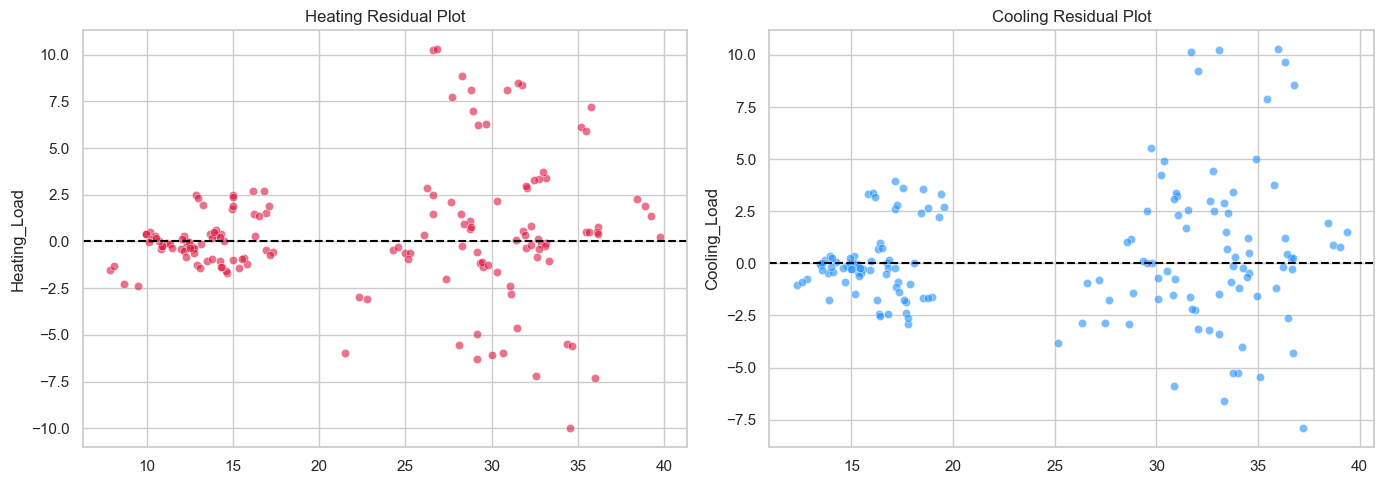

100%|██████████| 154/154 [03:28<00:00,  1.36s/it]

Top 2 Features Identified (Averaged): ['Overall_Height', 'Roof_Area']
[KNN - Both] Top 2 R2: 0.8084 | MAE: 3.3583 | MSE: 18.9600


In [71]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_base, y_both, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_val_cont_scaled = scaler.fit_transform(X_train_val[continuous_cols])
X_test_cont_scaled = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_val_pca_cont = pca.fit_transform(X_train_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_val_combined = np.hstack([X_train_val_pca_cont, X_train_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_val_full_scaled = np.hstack([X_train_val_cont_scaled, X_train_val[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

knn_params = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance']}
knn_grid = GridSearchCV(KNeighborsRegressor(), knn_params, cv=5, scoring='neg_mean_squared_error')
knn_grid.fit(X_train_val_combined, y_train_val)
knn_preds = knn_grid.predict(X_test_combined)

knn_train_preds = knn_grid.predict(X_train_val_combined)
print("Overfitting Check")
print(f"Train R2: {r2_score(y_train_val, knn_train_preds):.4f} | MAE: {mean_absolute_error(y_train_val, knn_train_preds):.4f}")
print(f"Test  R2: {r2_score(y_test, knn_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_preds):.4f}")
print(f"Gap (Train - Test): {r2_score(y_train_val, knn_train_preds) - r2_score(y_test, knn_preds):.4f}")
print()
print(f"Best Params: {knn_grid.best_params_}")
print()

print("Final Test Evaluation")
print(f"[KNN - Both] Base R2: {r2_score(y_test, knn_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_preds):.4f} | MSE: {mean_squared_error(y_test, knn_preds):.4f}")

res_heat = y_test['Heating_Load'] - knn_preds[:, 0]
res_cool = y_test['Cooling_Load']  - knn_preds[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=knn_preds[:, 0], y=res_heat, color='crimson', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='black', linestyle='--')
axes[0].set_title('Heating Residual Plot')

sns.scatterplot(x=knn_preds[:, 1], y=res_cool, color='dodgerblue', alpha=0.6, ax=axes[1])
axes[1].axhline(y=0, color='black', linestyle='--')
axes[1].set_title('Cooling Residual Plot')
plt.tight_layout()
plt.show()

knn_shap_model = KNeighborsRegressor(**knn_grid.best_params_).fit(X_train_val_full_scaled, y_train_val)
background = shap.kmeans(X_train_val_full_scaled, 25)
explainer = shap.KernelExplainer(knn_shap_model.predict, background)
shap_values = explainer.shap_values(X_test_full_scaled)

if isinstance(shap_values, list):
    fi_heat = np.abs(shap_values[0]).mean(axis=0)
    fi_cool = np.abs(shap_values[1]).mean(axis=0)
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    fi_heat = np.abs(shap_values[:, :, 0]).mean(axis=0)
    fi_cool = np.abs(shap_values[:, :, 1]).mean(axis=0)
else:
    fi_heat = np.abs(shap_values).mean(axis=0)
    fi_cool = fi_heat

fi_global = (fi_heat + fi_cool) / 2
top_2_indices = np.argsort(fi_global)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]

print(f"Top 2 Features Identified (Averaged): {top_2_features}")
scaler_top2 = StandardScaler()
X_train_val_top2 = scaler_top2.fit_transform(X_train_val[top_2_features])
X_test_top2 = scaler_top2.transform(X_test[top_2_features])

knn_top2 = KNeighborsRegressor(**knn_grid.best_params_).fit(X_train_val_top2, y_train_val)
knn_top2_preds = knn_top2.predict(X_test_top2)
print(f"[KNN - Both] Top 2 R2: {r2_score(y_test, knn_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, knn_top2_preds):.4f} | MSE: {mean_squared_error(y_test, knn_top2_preds):.4f}")

knn_both_r2 = r2_score(y_test, knn_preds)
knn_both_mae = mean_absolute_error(y_test, knn_preds)
knn_both_mse = mean_squared_error(y_test, knn_preds)

# Linear Regression (Heating Laod)

Validation Set Check
Train R2: 0.8947 | MAE: 2.3280
Val R2: 0.8714 | MAE: 2.6326
Gap (Train - Val): 0.0233

Final Test Evaluation
[LinReg - Heating] Base R2: 0.8959 | MAE: 2.2965 | MSE: 10.2336


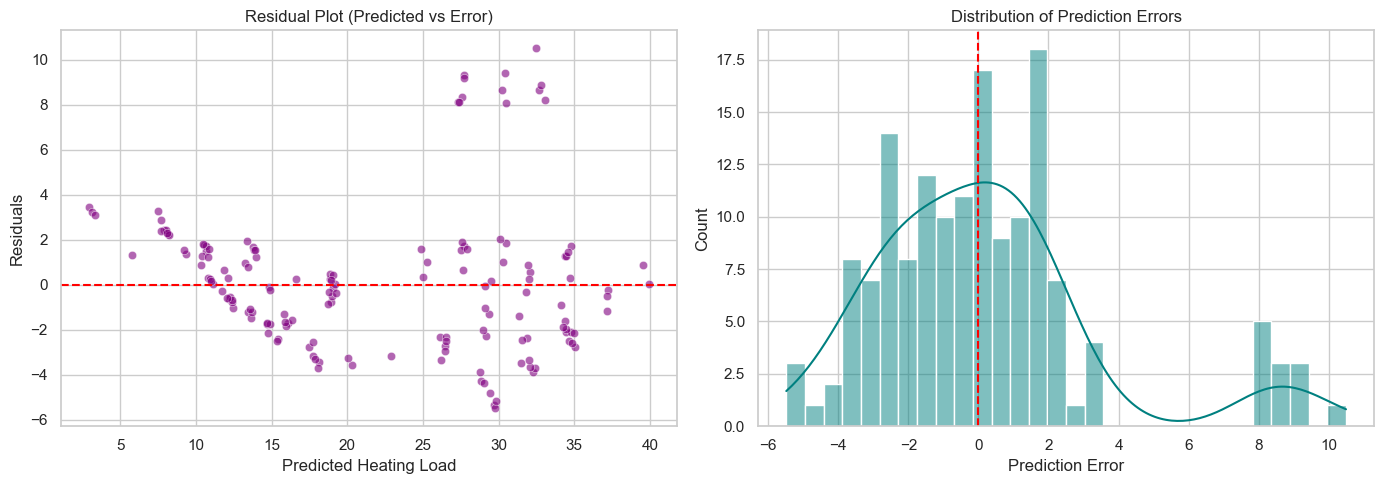

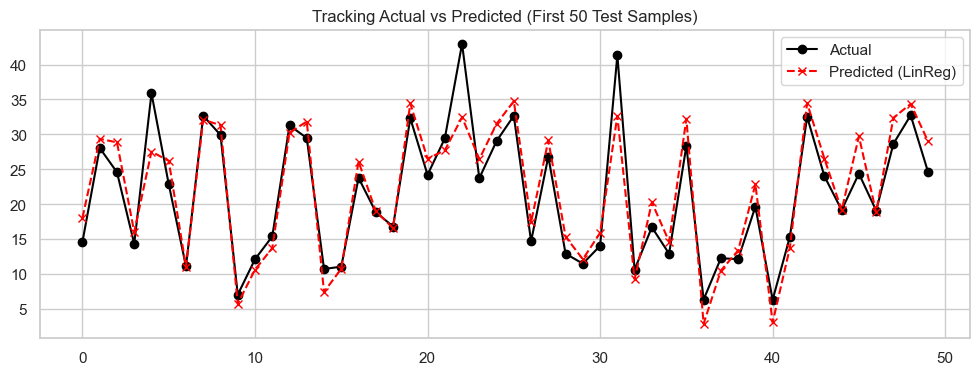

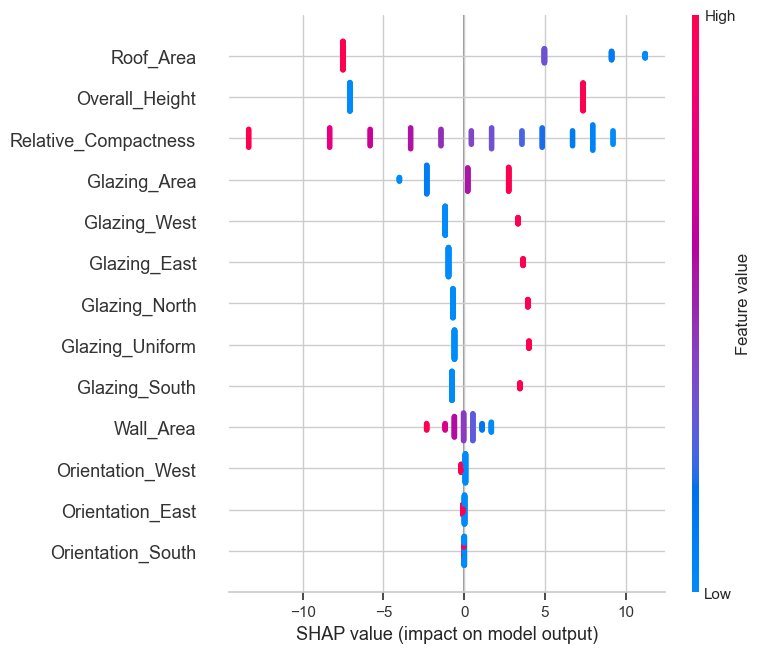

<Figure size 800x500 with 0 Axes>

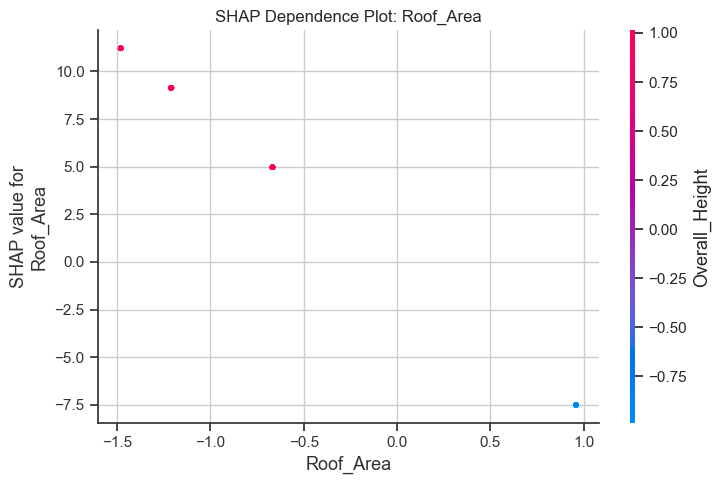

Top 2 Features Identified: ['Roof_Area', 'Overall_Height']
[LinReg - Heating] Top 2 R2: 0.8028 | MAE: 3.4766 | MSE: 19.3735


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X_base, y_heating, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

scaler = StandardScaler()
X_train_cont_scaled = scaler.fit_transform(X_train[continuous_cols])
X_val_cont_scaled = scaler.transform(X_val[continuous_cols])
X_test_cont_scaled = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_pca_cont = pca.fit_transform(X_train_cont_scaled)
X_val_pca_cont = pca.transform(X_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_combined = np.hstack([X_train_pca_cont, X_train[categorical_cols].values])
X_val_combined = np.hstack([X_val_pca_cont, X_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_full_scaled = np.hstack([X_train_cont_scaled, X_train[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

lin_reg = LinearRegression().fit(X_train_combined, y_train)

lin_train_preds = lin_reg.predict(X_train_combined)
lin_val_preds = lin_reg.predict(X_val_combined)
lin_preds = lin_reg.predict(X_test_combined)

print("Validation Set Check")
print(f"Train R2: {r2_score(y_train, lin_train_preds):.4f} | MAE: {mean_absolute_error(y_train, lin_train_preds):.4f}")
print(f"Val R2: {r2_score(y_val, lin_val_preds):.4f} | MAE: {mean_absolute_error(y_val,   lin_val_preds):.4f}")
print(f"Gap (Train - Val): {r2_score(y_train, lin_train_preds) - r2_score(y_val, lin_val_preds):.4f}")
print()

print("Final Test Evaluation")
print(f"[LinReg - Heating] Base R2: {r2_score(y_test, lin_preds):.4f} | MAE: {mean_absolute_error(y_test, lin_preds):.4f} | MSE: {mean_squared_error(y_test, lin_preds):.4f}")

residuals = y_test - lin_preds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=lin_preds, y=residuals, color='purple', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Predicted vs Error)')
axes[0].set_xlabel('Predicted Heating Load')
axes[0].set_ylabel('Residuals')

sns.histplot(residuals, bins=30, kde=True, color='teal', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_title('Distribution of Prediction Errors')
axes[1].set_xlabel('Prediction Error')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(50), y_test.values[:50], label='Actual', marker='o', color='black')
plt.plot(range(50), lin_preds[:50], label='Predicted (LinReg)', marker='x', color='red', linestyle='--')
plt.title('Tracking Actual vs Predicted (First 50 Test Samples)')
plt.legend()
plt.show()

lin_shap_model = LinearRegression().fit(X_train_full_scaled, y_train)
explainer = shap.LinearExplainer(lin_shap_model, X_train_full_scaled)
shap_values = explainer.shap_values(X_test_full_scaled)

plt.figure(figsize=(8, 5))
plt.title("SHAP Summary: Linear Regression (Heating)")
shap.summary_plot(shap_values, X_test_full_scaled, feature_names=full_feature_names)

fi = np.abs(shap_values).mean(axis=0)
top_2_indices = np.argsort(fi)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]

plt.figure(figsize=(8, 5))
shap.dependence_plot(top_2_features[0], shap_values, X_test_full_scaled, feature_names=full_feature_names, show=False)
plt.title(f'SHAP Dependence Plot: {top_2_features[0]}')
plt.tight_layout()
plt.show()

print(f"Top 2 Features Identified: {top_2_features}")
scaler_top2 = StandardScaler()
X_train_top2 = scaler_top2.fit_transform(X_train[top_2_features])
X_test_top2 = scaler_top2.transform(X_test[top_2_features])

lin_top2 = LinearRegression().fit(X_train_top2, y_train)
lin_top2_preds = lin_top2.predict(X_test_top2)
print(f"[LinReg - Heating] Top 2 R2: {r2_score(y_test, lin_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, lin_top2_preds):.4f} | MSE: {mean_squared_error(y_test, lin_top2_preds):.4f}")

lin_heat_r2 = r2_score(y_test, lin_preds)
lin_heat_mae = mean_absolute_error(y_test, lin_preds)
lin_heat_mse = mean_squared_error(y_test, lin_preds)

# Linear Regression (Cooling Load)

Validation Set Check
Train R2: 0.8426 | MAE: 2.6480
Val R2: 0.8651 | MAE: 2.5788
Gap (Train - Val): -0.0226

Final Test Evaluation
[LinReg - Cooling] Base R2: 0.8352 | MAE: 2.7645 | MSE: 15.3423


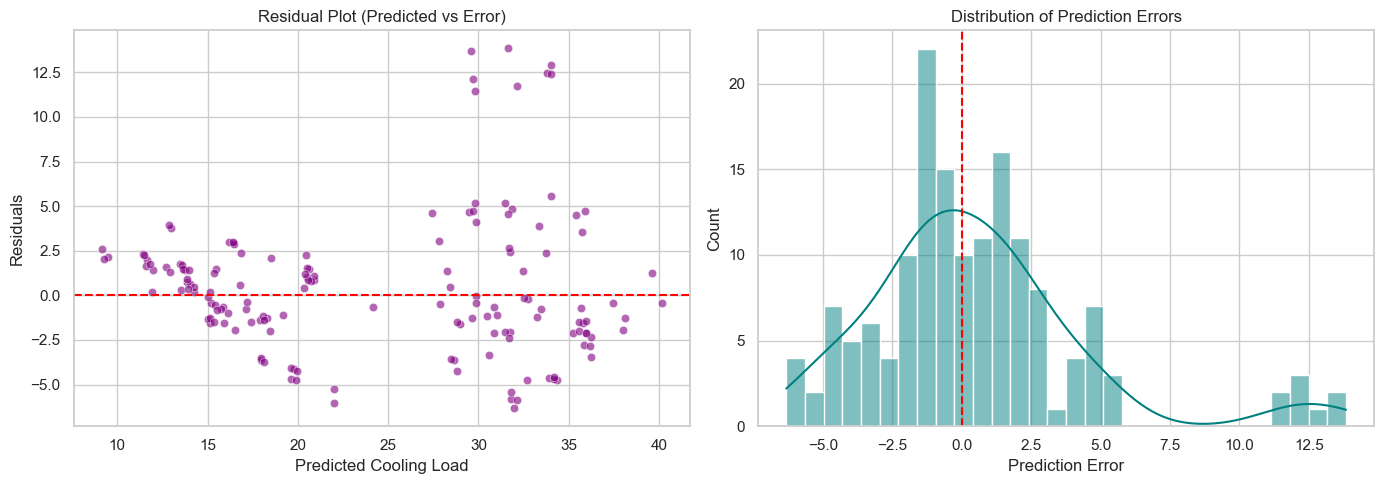

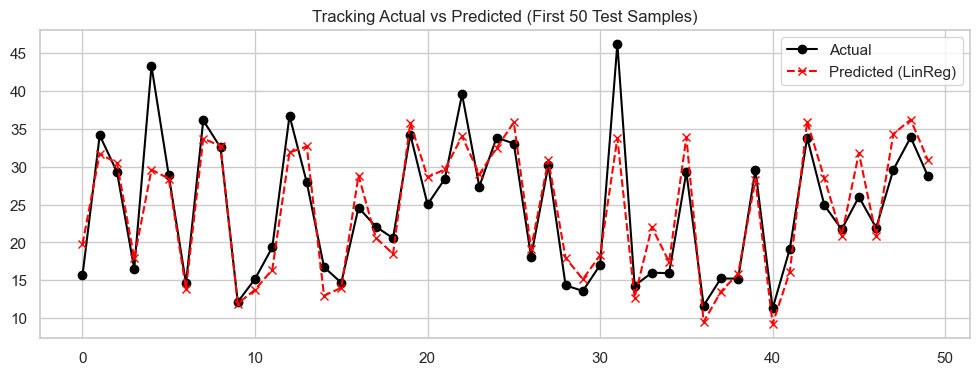

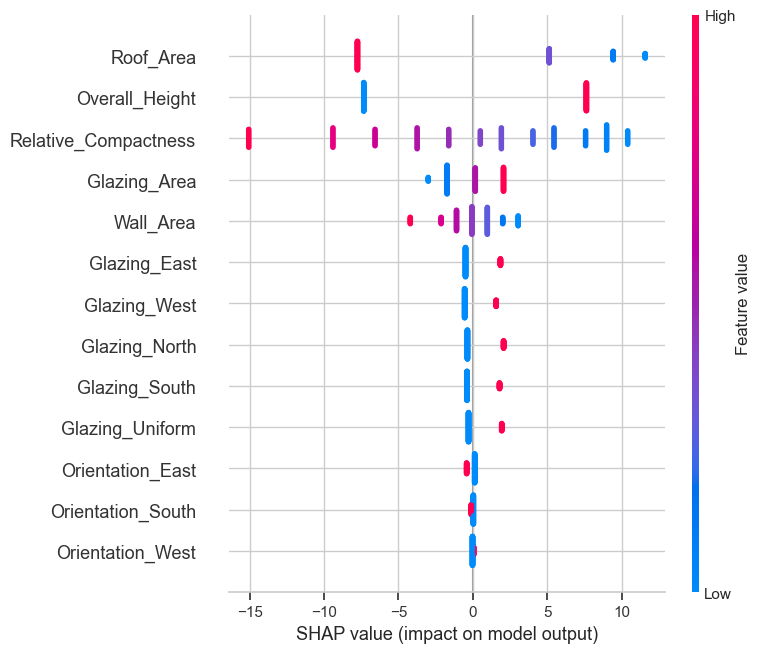

<Figure size 800x500 with 0 Axes>

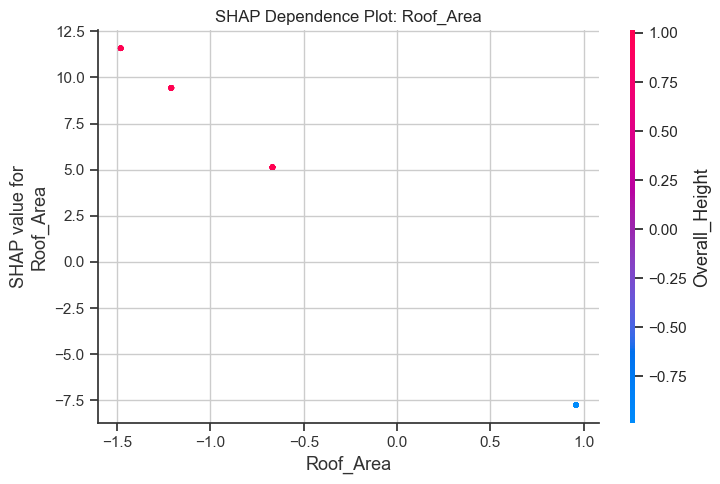

Top 2 Features Identified: ['Roof_Area', 'Overall_Height']
[LinReg - Cooling] Top 2 R2: 0.7955 | MAE: 3.2871 | MSE: 19.0387


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X_base, y_cooling, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

scaler = StandardScaler()
X_train_cont_scaled = scaler.fit_transform(X_train[continuous_cols])
X_val_cont_scaled = scaler.transform(X_val[continuous_cols])
X_test_cont_scaled  = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_pca_cont = pca.fit_transform(X_train_cont_scaled)
X_val_pca_cont = pca.transform(X_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_combined = np.hstack([X_train_pca_cont, X_train[categorical_cols].values])
X_val_combined = np.hstack([X_val_pca_cont, X_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_full_scaled = np.hstack([X_train_cont_scaled, X_train[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

lin_reg = LinearRegression().fit(X_train_combined, y_train)

lin_train_preds = lin_reg.predict(X_train_combined)
lin_val_preds = lin_reg.predict(X_val_combined)
lin_preds = lin_reg.predict(X_test_combined)

print("Validation Set Check")
print(f"Train R2: {r2_score(y_train, lin_train_preds):.4f} | MAE: {mean_absolute_error(y_train, lin_train_preds):.4f}")
print(f"Val R2: {r2_score(y_val, lin_val_preds):.4f} | MAE: {mean_absolute_error(y_val,   lin_val_preds):.4f}")
print(f"Gap (Train - Val): {r2_score(y_train, lin_train_preds) - r2_score(y_val, lin_val_preds):.4f}")
print()

print("Final Test Evaluation")
print(f"[LinReg - Cooling] Base R2: {r2_score(y_test, lin_preds):.4f} | MAE: {mean_absolute_error(y_test, lin_preds):.4f} | MSE: {mean_squared_error(y_test, lin_preds):.4f}")

residuals = y_test - lin_preds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=lin_preds, y=residuals, color='purple', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Predicted vs Error)')
axes[0].set_xlabel('Predicted Cooling Load')
axes[0].set_ylabel('Residuals')

sns.histplot(residuals, bins=30, kde=True, color='teal', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle='--')
axes[1].set_title('Distribution of Prediction Errors')
axes[1].set_xlabel('Prediction Error')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(50), y_test.values[:50], label='Actual', marker='o', color='black')
plt.plot(range(50), lin_preds[:50], label='Predicted (LinReg)', marker='x', color='red', linestyle='--')
plt.title('Tracking Actual vs Predicted (First 50 Test Samples)')
plt.legend()
plt.show()

lin_shap_model = LinearRegression().fit(X_train_full_scaled, y_train)
explainer = shap.LinearExplainer(lin_shap_model, X_train_full_scaled)
shap_values = explainer.shap_values(X_test_full_scaled)

plt.figure(figsize=(8, 5))
plt.title("SHAP Summary: Linear Regression (Cooling)")
shap.summary_plot(shap_values, X_test_full_scaled, feature_names=full_feature_names)

fi = np.abs(shap_values).mean(axis=0)
top_2_indices = np.argsort(fi)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]

plt.figure(figsize=(8, 5))
shap.dependence_plot(top_2_features[0], shap_values, X_test_full_scaled, feature_names=full_feature_names, show=False)
plt.title(f'SHAP Dependence Plot: {top_2_features[0]}')
plt.tight_layout()
plt.show()

print(f"Top 2 Features Identified: {top_2_features}")
scaler_top2 = StandardScaler()
X_train_top2 = scaler_top2.fit_transform(X_train[top_2_features])
X_test_top2 = scaler_top2.transform(X_test[top_2_features])

lin_top2 = LinearRegression().fit(X_train_top2, y_train)
lin_top2_preds = lin_top2.predict(X_test_top2)
print(f"[LinReg - Cooling] Top 2 R2: {r2_score(y_test, lin_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, lin_top2_preds):.4f} | MSE: {mean_squared_error(y_test, lin_top2_preds):.4f}")


lin_cool_r2 = r2_score(y_test, lin_preds)
lin_cool_mae = mean_absolute_error(y_test, lin_preds)
lin_cool_mse = mean_squared_error(y_test, lin_preds)

# Linear Regression (Both Target Variables)

Validation Set Check
Train R2: 0.8686 | MAE: 2.4880
Val R2: 0.8683 | MAE: 2.6057
Gap (Train - Val): 0.0004

Final Test Evaluation
[LinReg - Both] Base R2: 0.8655 | MAE: 2.5305 | MSE: 12.7880


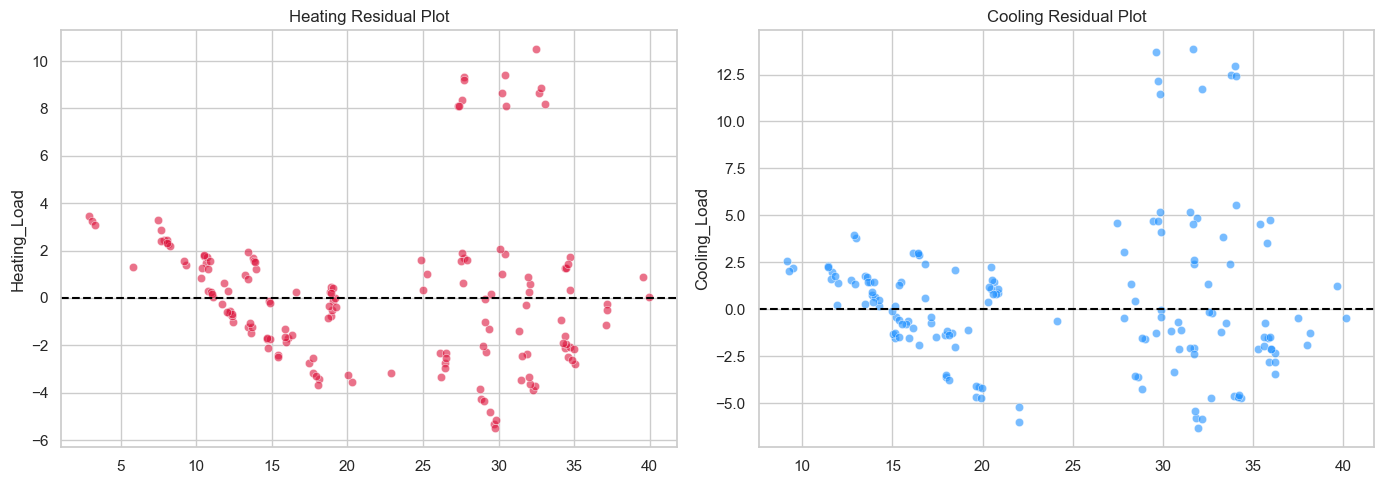

Top 2 Features Identified (Averaged): ['Roof_Area', 'Overall_Height']
[LinReg - Both] Top 2 R2: 0.7992 | MAE: 3.3819 | MSE: 19.2061


In [74]:
X_train, X_temp, y_train, y_temp = train_test_split(X_base, y_both, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

scaler = StandardScaler()
X_train_cont_scaled = scaler.fit_transform(X_train[continuous_cols])
X_val_cont_scaled = scaler.transform(X_val[continuous_cols])
X_test_cont_scaled = scaler.transform(X_test[continuous_cols])

pca = PCA(n_components=0.95, random_state=42)
X_train_pca_cont = pca.fit_transform(X_train_cont_scaled)
X_val_pca_cont = pca.transform(X_val_cont_scaled)
X_test_pca_cont = pca.transform(X_test_cont_scaled)

X_train_combined = np.hstack([X_train_pca_cont, X_train[categorical_cols].values])
X_val_combined = np.hstack([X_val_pca_cont, X_val[categorical_cols].values])
X_test_combined = np.hstack([X_test_pca_cont, X_test[categorical_cols].values])

X_train_full_scaled = np.hstack([X_train_cont_scaled, X_train[categorical_cols].values])
X_test_full_scaled = np.hstack([X_test_cont_scaled, X_test[categorical_cols].values])

lin_reg = LinearRegression().fit(X_train_combined, y_train)

lin_train_preds = lin_reg.predict(X_train_combined)
lin_val_preds = lin_reg.predict(X_val_combined)
lin_preds = lin_reg.predict(X_test_combined)

print("Validation Set Check")
print(f"Train R2: {r2_score(y_train, lin_train_preds):.4f} | MAE: {mean_absolute_error(y_train, lin_train_preds):.4f}")
print(f"Val R2: {r2_score(y_val,   lin_val_preds):.4f} | MAE: {mean_absolute_error(y_val,   lin_val_preds):.4f}")
print(f"Gap (Train - Val): {r2_score(y_train, lin_train_preds) - r2_score(y_val, lin_val_preds):.4f}")
print()

print("Final Test Evaluation")
print(f"[LinReg - Both] Base R2: {r2_score(y_test, lin_preds):.4f} | MAE: {mean_absolute_error(y_test, lin_preds):.4f} | MSE: {mean_squared_error(y_test, lin_preds):.4f}")

res_heat = y_test['Heating_Load'] - lin_preds[:, 0]
res_cool = y_test['Cooling_Load'] - lin_preds[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=lin_preds[:, 0], y=res_heat, color='crimson', alpha=0.6, ax=axes[0])
axes[0].axhline(y=0, color='black', linestyle='--')
axes[0].set_title('Heating Residual Plot')

sns.scatterplot(x=lin_preds[:, 1], y=res_cool, color='dodgerblue', alpha=0.6, ax=axes[1])
axes[1].axhline(y=0, color='black', linestyle='--')
axes[1].set_title('Cooling Residual Plot')
plt.tight_layout()
plt.show()

multi_lin = MultiOutputRegressor(LinearRegression()).fit(X_train_full_scaled, y_train)
explainer_heat = shap.LinearExplainer(multi_lin.estimators_[0], X_train_full_scaled)
explainer_cool = shap.LinearExplainer(multi_lin.estimators_[1], X_train_full_scaled)

shap_heat = np.abs(explainer_heat.shap_values(X_test_full_scaled)).mean(axis=0)
shap_cool = np.abs(explainer_cool.shap_values(X_test_full_scaled)).mean(axis=0)
fi_global = (shap_heat + shap_cool) / 2

top_2_indices = np.argsort(fi_global)[::-1][:2]
top_2_features = [full_feature_names[i] for i in top_2_indices]
print(f"Top 2 Features Identified (Averaged): {top_2_features}")

scaler_top2 = StandardScaler()
X_train_top2 = scaler_top2.fit_transform(X_train[top_2_features])
X_test_top2  = scaler_top2.transform(X_test[top_2_features])

lin_top2 = LinearRegression().fit(X_train_top2, y_train)
lin_top2_preds = lin_top2.predict(X_test_top2)
print(f"[LinReg - Both] Top 2 R2: {r2_score(y_test, lin_top2_preds):.4f} | MAE: {mean_absolute_error(y_test, lin_top2_preds):.4f} | MSE: {mean_squared_error(y_test, lin_top2_preds):.4f}")

lin_both_r2  = r2_score(y_test, lin_preds)
lin_both_mae = mean_absolute_error(y_test, lin_preds)
lin_both_mse = mean_squared_error(y_test, lin_preds)

# Model Comparison Graphs

  Model  Target       R2      MAE       MSE
 LinReg Heating 0.895860 2.296480 10.233645
 LinReg Cooling 0.835192 2.764535 15.342267
 LinReg    Both 0.865526 2.530508 12.787956
    KNN Heating 0.912279 1.960325  9.143315
    KNN Cooling 0.908252 1.964227  8.501147
    KNN    Both 0.899045 2.085988  9.938921
XGBoost Heating 0.998401 0.293633  0.166683
XGBoost Cooling 0.970436 0.992048  2.739320
XGBoost    Both 0.984418 0.642841  1.453002


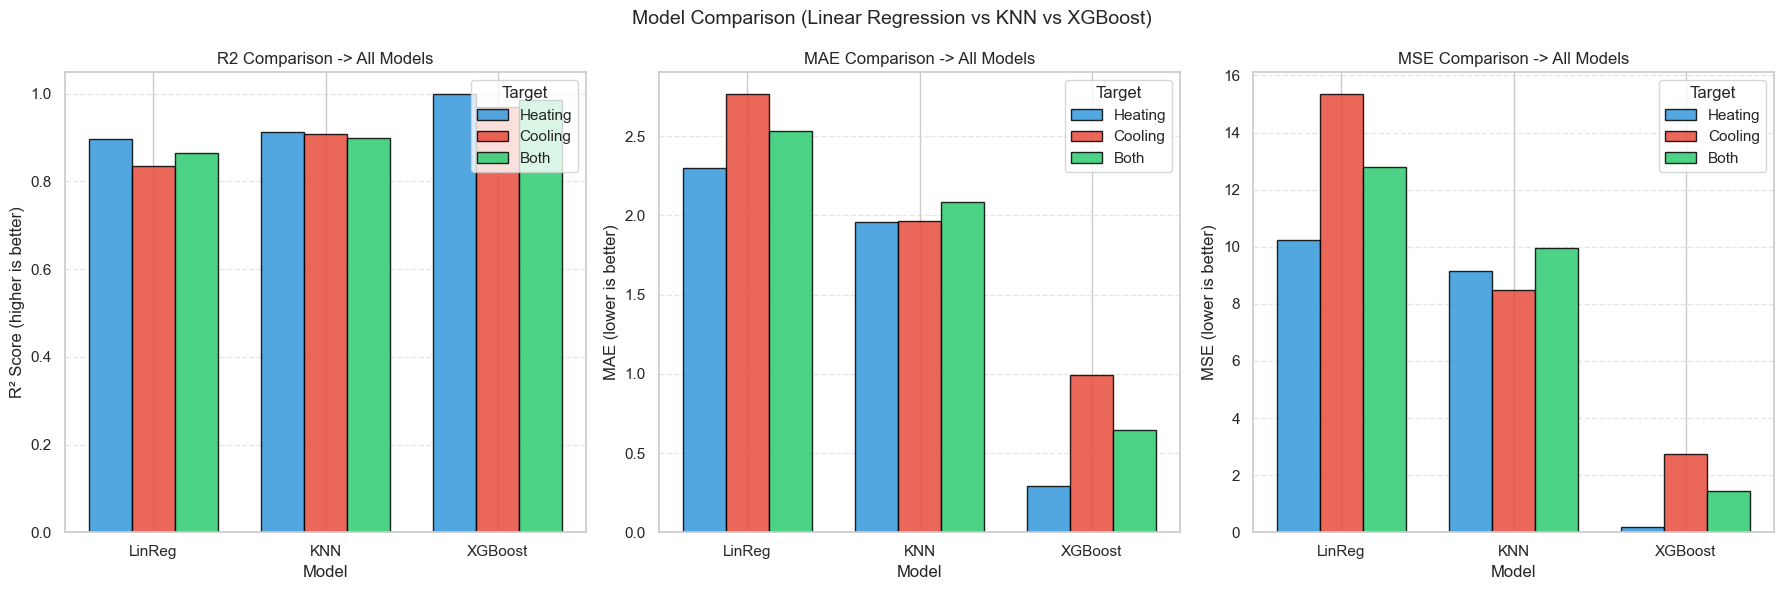

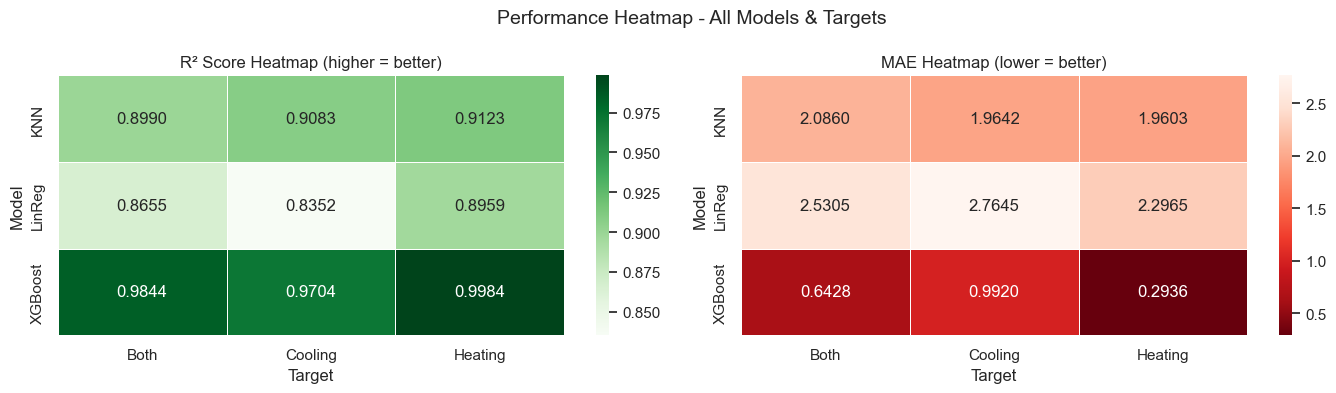


Best Model Per Target
Heating: Best = XGBoost | R²=0.9984 | MAE=0.2936
Cooling: Best = XGBoost | R²=0.9704 | MAE=0.9920
Both: Best = XGBoost | R²=0.9844 | MAE=0.6428


In [ ]:
results = {
    'Model': [
        'LinReg',  'LinReg',  'LinReg',
        'KNN',     'KNN',     'KNN',
        'XGBoost', 'XGBoost', 'XGBoost'
    ],
    'Target': [
        'Heating', 'Cooling', 'Both',
        'Heating', 'Cooling', 'Both',
        'Heating', 'Cooling', 'Both'
    ],
    'R2': [
        lin_heat_r2,  lin_cool_r2,  lin_both_r2,
        knn_heat_r2,  knn_cool_r2,  knn_both_r2,
        xgb_heat_r2,  xgb_cool_r2,  xgb_both_r2
    ],
    'MAE': [
        lin_heat_mae, lin_cool_mae, lin_both_mae,
        knn_heat_mae, knn_cool_mae, knn_both_mae,
        xgb_heat_mae, xgb_cool_mae, xgb_both_mae
    ],
    'MSE': [
        lin_heat_mse, lin_cool_mse, lin_both_mse,
        knn_heat_mse, knn_cool_mse, knn_both_mse,
        xgb_heat_mse, xgb_cool_mse, xgb_both_mse
    ]
}

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
targets = ['Heating', 'Cooling', 'Both']
colors = ['#3498db', '#e74c3c', '#2ecc71']
metrics = [('R2', 'R² Score (higher is better)', True),
             ('MAE', 'MAE (lower is better)', False),
             ('MSE', 'MSE (lower is better)', False)]

for ax, (metric, ylabel, higher_better) in zip(axes, metrics):
    for i, target in enumerate(targets):
        subset = results_df[results_df['Target'] == target]
        x = np.arange(len(subset))
        bars = ax.bar(x + i * 0.25, subset[metric], width=0.25,
                        label=target, color=colors[i], alpha=0.85, edgecolor='black')

    ax.set_title(f'{metric} Comparison -> All Models')
    ax.set_xlabel('Model')
    ax.set_ylabel(ylabel)
    ax.set_xticks(np.arange(3) + 0.25)
    ax.set_xticklabels(['LinReg', 'KNN', 'XGBoost'])
    ax.legend(title='Target')
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle('Model Comparison (Linear Regression vs KNN vs XGBoost)', fontsize=14)
plt.tight_layout()
plt.show()

pivot_r2 = results_df.pivot(index='Model', columns='Target', values='R2')
pivot_mae = results_df.pivot(index='Model', columns='Target', values='MAE')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.heatmap(pivot_r2,  annot=True, fmt='.4f', cmap='Greens', ax=axes[0], linewidths=0.5)
axes[0].set_title('R² Score Heatmap (higher = better)')

sns.heatmap(pivot_mae, annot=True, fmt='.4f', cmap='Reds_r', ax=axes[1], linewidths=0.5)
axes[1].set_title('MAE Heatmap (lower = better)')

plt.suptitle('Performance Heatmap - All Models & Targets', fontsize=14)
plt.tight_layout()
plt.show()

print("\nBest Model Per Target")
for target in targets:
    subset = results_df[results_df['Target'] == target]
    best_row = subset.loc[subset['R2'].idxmax()]
    print(f"{target}: Best = {best_row['Model']} | R²={best_row['R2']:.4f} | MAE={best_row['MAE']:.4f}")
    